In [1]:
# Colab
# from google.colab import drive
# drive.mount('/content/drive')
# root = '/content/drive/MyDrive/wirelessLLM'
# import os
# os.chdir(root)

In [2]:
#Kaggle 
root = '/kaggle/working'
input_path = '/kaggle/input/config'
!cp -r {input_path} {root}
import os
os.chdir(root)

In [3]:
!pip install -r {root}/config/requirements.txt
!pip install optuna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.3/112.3 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.7/323.7 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 68.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.4/308.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 38.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 48.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 67.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 

# utils.py

In [4]:
import yaml
from typing import Any, Dict
from dataclasses import dataclass
from typing import List, Dict, Tuple, Optional
import numpy as np
from OpenGL.GL import *
from OpenGL.GLU import *
import math

# ============================================================================
# APPROACH 1: PROCEDURAL DRONE MODEL (Recommended - No External Files)
# ============================================================================

class ProceduralDroneModel:
    """
    Creates a detailed drone model using OpenGL primitives.
    No external files needed - all geometry is generated procedurally.
    """

    def __init__(self):
        self.body_size = 10
        self.arm_length = 15
        self.arm_thickness = 1.5
        self.rotor_radius = 5
        self.rotor_thickness = 0.3

    def draw_box(self, width, height, depth):
        """Draw a box centered at origin"""
        glBegin(GL_QUADS)

        # Front face
        glNormal3f(0, 0, 1)
        glVertex3f(-width/2, -height/2, depth/2)
        glVertex3f(width/2, -height/2, depth/2)
        glVertex3f(width/2, height/2, depth/2)
        glVertex3f(-width/2, height/2, depth/2)

        # Back face
        glNormal3f(0, 0, -1)
        glVertex3f(-width/2, -height/2, -depth/2)
        glVertex3f(-width/2, height/2, -depth/2)
        glVertex3f(width/2, height/2, -depth/2)
        glVertex3f(width/2, -height/2, -depth/2)

        # Top face
        glNormal3f(0, 1, 0)
        glVertex3f(-width/2, height/2, -depth/2)
        glVertex3f(-width/2, height/2, depth/2)
        glVertex3f(width/2, height/2, depth/2)
        glVertex3f(width/2, height/2, -depth/2)

        # Bottom face
        glNormal3f(0, -1, 0)
        glVertex3f(-width/2, -height/2, -depth/2)
        glVertex3f(width/2, -height/2, -depth/2)
        glVertex3f(width/2, -height/2, depth/2)
        glVertex3f(-width/2, -height/2, depth/2)

        # Right face
        glNormal3f(1, 0, 0)
        glVertex3f(width/2, -height/2, -depth/2)
        glVertex3f(width/2, height/2, -depth/2)
        glVertex3f(width/2, height/2, depth/2)
        glVertex3f(width/2, -height/2, depth/2)

        # Left face
        glNormal3f(-1, 0, 0)
        glVertex3f(-width/2, -height/2, -depth/2)
        glVertex3f(-width/2, -height/2, depth/2)
        glVertex3f(-width/2, height/2, depth/2)
        glVertex3f(-width/2, height/2, -depth/2)

        glEnd()

    def draw_cylinder(self, radius, height, slices=16):
        """Draw a cylinder"""
        quad = gluNewQuadric()
        gluCylinder(quad, radius, radius, height, slices, 1)

        # Draw caps
        glPushMatrix()
        glRotatef(180, 1, 0, 0)
        gluDisk(quad, 0, radius, slices, 1)
        glPopMatrix()

        glPushMatrix()
        glTranslatef(0, 0, height)
        gluDisk(quad, 0, radius, slices, 1)
        glPopMatrix()

        gluDeleteQuadric(quad)

    def draw_sphere(self, radius, slices=16, stacks=16):
        """Draw a sphere"""
        quad = gluNewQuadric()
        gluSphere(quad, radius, slices, stacks)
        gluDeleteQuadric(quad)

    def draw_rotor(self, animation_angle):
        """Draw a single rotor with spinning blades"""
        # Rotor motor housing
        glColor3f(0.2, 0.2, 0.2)
        self.draw_cylinder(self.rotor_radius * 0.3, 2, 12)

        # Rotor blades (spinning)
        glPushMatrix()
        glTranslatef(0, 0, 2)
        glRotatef(animation_angle, 0, 0, 1)

        glColor3f(0.1, 0.1, 0.15)
        for i in range(2):  # 2 blades
            glPushMatrix()
            glRotatef(i * 180, 0, 0, 1)
            glTranslatef(self.rotor_radius * 0.5, 0, 0)

            # Blade shape (elongated box)
            self.draw_box(self.rotor_radius * 1.2, 1, self.rotor_thickness)

            glPopMatrix()

        glPopMatrix()

    def draw_arm(self):
        """Draw a single drone arm"""
        glColor3f(0.3, 0.3, 0.35)

        # Main arm tube
        glPushMatrix()
        glRotatef(90, 0, 1, 0)
        self.draw_cylinder(self.arm_thickness, self.arm_length, 8)
        glPopMatrix()

        # Arm tip connector
        glPushMatrix()
        glTranslatef(self.arm_length, 0, 0)
        glColor3f(0.25, 0.25, 0.3)
        self.draw_sphere(self.arm_thickness * 1.3, 8, 8)
        glPopMatrix()

    def draw_body(self):
        """Draw the main drone body"""
        # Main body (slightly rounded box)
        glColor3f(0.4, 0.4, 0.45)
        self.draw_box(self.body_size, self.body_size * 0.6, self.body_size)

        # Top camera/sensor dome
        glPushMatrix()
        glTranslatef(0, self.body_size * 0.35, 0)
        glColor3f(0.2, 0.2, 0.25)
        glScalef(1, 0.5, 1)
        self.draw_sphere(self.body_size * 0.3, 12, 12)
        glPopMatrix()

        # Bottom landing gear
        glColor3f(0.3, 0.3, 0.3)
        for i in range(4):
            angle = i * 90 + 45
            rad = math.radians(angle)
            x = math.cos(rad) * self.body_size * 0.4
            z = math.sin(rad) * self.body_size * 0.4

            glPushMatrix()
            glTranslatef(x, -self.body_size * 0.4, z)
            glRotatef(90, 1, 0, 0)
            self.draw_cylinder(0.5, 2, 6)
            glPopMatrix()

    def draw(self, animation_time, uav_id, is_selected=False):
        """
        Draw the complete drone model

        Args:
            animation_time: Time value for animations
            uav_id: UAV ID for unique rotations
            is_selected: Whether this UAV is selected
        """
        # Rotation for rotor animation (faster spin)
        rotor_angle = (animation_time * 720 + uav_id * 120) % 360

        # Slight hovering animation
        hover_offset = math.sin(animation_time * 2 + uav_id) * 1.5
        glTranslatef(0, hover_offset, 0)

        # Draw main body with selection highlight
        if is_selected:
            # Pulsing glow effect for selected UAV
            pulse = 0.5 + 0.5 * math.sin(animation_time * 3)
            glColor3f(1.0, 0.8 + pulse * 0.2, 0.4)

            # # Draw larger translucent sphere as selection indicator
            # glDisable(GL_LIGHTING)
            # glEnable(GL_BLEND)
            # glBlendFunc(GL_SRC_ALPHA, GL_ONE_MINUS_SRC_ALPHA)
            # glColor4f(1.0, 0.8, 0.4, 0.3)
            # self.draw_sphere(self.body_size * 1.3, 16, 16)
            # glEnable(GL_LIGHTING)

        self.draw_body()

        # Draw 4 arms with rotors at cardinal directions
        for i in range(4):
            angle = i * 90 + 45  # Offset by 45 degrees

            glPushMatrix()
            glRotatef(angle, 0, 1, 0)

            # Draw arm
            self.draw_arm()

            # Draw rotor at end of arm
            glTranslatef(self.arm_length, 3, 0)
            # Alternate rotor spin directions for realistic physics
            rotor_direction = 1 if i % 2 == 0 else -1
            self.draw_rotor(rotor_angle * rotor_direction)

            glPopMatrix()


# ============================================================================
# APPROACH 2: OBJ MODEL LOADER (Optional - Better Quality)
# ============================================================================

class OBJModelLoader:
    """
    Load and render .obj 3D model files.
    Use this if you have a high-quality drone model.
    """

    def __init__(self, filename=None):
        self.vertices = []
        self.normals = []
        self.texcoords = []
        self.faces = []
        self.display_list = None

        if filename:
            self.load(filename)

    def load(self, filename):
        """Load an OBJ file"""
        self.vertices = []
        self.normals = []
        self.texcoords = []
        self.faces = []

        try:
            with open(filename, 'r') as f:
                for line in f:
                    if line.startswith('#'):
                        continue

                    values = line.split()
                    if not values:
                        continue

                    if values[0] == 'v':
                        # Vertex
                        v = [float(x) for x in values[1:4]]
                        self.vertices.append(v)

                    elif values[0] == 'vn':
                        # Normal
                        n = [float(x) for x in values[1:4]]
                        self.normals.append(n)

                    elif values[0] == 'vt':
                        # Texture coordinate
                        t = [float(x) for x in values[1:3]]
                        self.texcoords.append(t)

                    elif values[0] == 'f':
                        # Face
                        face = []
                        for v in values[1:]:
                            w = v.split('/')
                            face.append([int(w[0]) - 1,  # vertex index
                                       int(w[1]) - 1 if len(w) >= 2 and w[1] else -1,  # texcoord
                                       int(w[2]) - 1 if len(w) >= 3 and w[2] else -1])  # normal
                        self.faces.append(face)

            print(f"Loaded {len(self.vertices)} vertices, {len(self.faces)} faces from {filename}")

            # Create display list for faster rendering
            self.create_display_list()

        except FileNotFoundError:
            print(f"Error: Model file {filename} not found!")
        except Exception as e:
            print(f"Error loading model: {e}")

    def create_display_list(self):
        """Create OpenGL display list for faster rendering"""
        if not self.vertices:
            return

        self.display_list = glGenLists(1)
        glNewList(self.display_list, GL_COMPILE)

        glBegin(GL_TRIANGLES)
        for face in self.faces:
            for vertex in face:
                v_idx, t_idx, n_idx = vertex

                if n_idx >= 0 and n_idx < len(self.normals):
                    glNormal3fv(self.normals[n_idx])

                if v_idx >= 0 and v_idx < len(self.vertices):
                    glVertex3fv(self.vertices[v_idx])
        glEnd()

        glEndList()

    def draw(self, animation_time, uav_id, is_selected=False, scale=1.0):
        """Draw the loaded model"""
        if self.display_list:
            glPushMatrix()

            # Scale the model
            glScalef(scale, scale, scale)

            # Selection highlight
            if is_selected:
                glColor3f(1.0, 0.8, 0.4)
            else:
                glColor3f(0.8, 0.8, 0.8)

            # Draw the model
            glCallList(self.display_list)

            glPopMatrix()


class NestedDict:
    """Convert nested dict to object with dot notation access"""
    def __init__(self, data: Dict):
        for key, value in data.items():
            if isinstance(value, dict):
                setattr(self, key, NestedDict(value))
            else:
                setattr(self, key, self._convert_value(value))

    def _convert_value(self, value):
        """Convert string numbers to appropriate types"""
        if isinstance(value, str):
            # Try to convert scientific notation strings to float
            try:
                if 'e' in value.lower() or '.' in value:
                    return float(value)
                elif value.isdigit():
                    return int(value)
            except ValueError:
                pass
        return value

    def __getitem__(self, key):
        """Enable subscript access like dict[key]"""
        return getattr(self, key)

    def __setitem__(self, key, value):
        """Enable subscript assignment like dict[key] = value"""
        setattr(self, key, value)

    def __contains__(self, key):
        """Enable 'in' operator"""
        return hasattr(self, key)

    def get(self, key, default=None):
        """Dict-like get method"""
        return getattr(self, key, default)

    def __repr__(self):
        attrs = {k: v for k, v in self.__dict__.items()}
        return f"NestedDict({attrs})"

class Configuration:
    """Simple configuration class with nested YAML support and type conversion"""

    def __init__(self, config_path: str):
        self.config_path = config_path
        self._load_config()

    def _load_config(self):
        """Load YAML config and set nested attributes"""
        try:
            with open(self.config_path, 'r') as f:
                config_data = yaml.safe_load(f) or {}

            # Set all config keys as attributes (with nested support)
            for key, value in config_data.items():
                if isinstance(value, dict):
                    setattr(self, key, NestedDict(value))
                else:
                    setattr(self, key, self._convert_value(value))

            print(f"✓ Loaded config from {self.config_path}")

        except FileNotFoundError:
            print(f"❌ Config file not found: {self.config_path}")
        except yaml.YAMLError as e:
            print(f"❌ Error parsing YAML: {e}")

    def _convert_value(self, value):
        """Convert string numbers to appropriate types"""
        if isinstance(value, str):
            # Try to convert scientific notation strings to float
            try:
                if 'e' in value.lower() or '.' in value:
                    return float(value)
                elif value.isdigit():
                    return int(value)
            except ValueError:
                pass
        return value

    def get(self, key: str, default: Any = None) -> Any:
        """Get attribute with default value (supports dot notation)"""
        if '.' in key:
            # Handle nested access like 'qos.embb.min_rate'
            keys = key.split('.')
            obj = self
            for k in keys:
                if hasattr(obj, k):
                    obj = getattr(obj, k)
                else:
                    return default
            return obj
        else:
            return getattr(self, key, default)

    def __repr__(self):
        attrs = {k: v for k, v in self.__dict__.items() if not k.startswith('_')}
        return f"Configuration({attrs})"

@dataclass
class Packet:
    """Individual packet in queue"""
    ue_id: int
    size: int  # bytes
    enqueue_time: float  # seconds
    slice_type: str
    deadline: Optional[float] = None  # For URLLC


from collections import deque
class QueueingModel:
    """
    Per-DA queuing with M/M/1 approximation
    Makes bandwidth allocation strategic!
    """
    def __init__(self, buffer_size=100):
        self.buffer_size = buffer_size
        self.queues = {}  # {da_id: deque of Packets}
        self.dropped_packets = {}  # Track drops per DA
        self.serviced_packets = {}  # Track successful transmissions

    def enqueue_packet(self, da_id: int, packet: Packet) -> bool:
        """
        Try to enqueue packet
        Returns: True if enqueued, False if dropped (buffer overflow)
        """
        if da_id not in self.queues:
            self.queues[da_id] = deque(maxlen=self.buffer_size)
            self.dropped_packets[da_id] = 0
            self.serviced_packets[da_id] = 0

        if len(self.queues[da_id]) >= self.buffer_size:
            # Buffer overflow - packet dropped
            self.dropped_packets[da_id] += 1
            return False

        self.queues[da_id].append(packet)
        return True

    def service_packets(self, da_id: int, service_rate: float,
                    timestep: float, current_time: float) -> List[Tuple[Packet, float]]:
        """
        Service packets from queue

        Args:
            da_id: Demand area ID
            service_rate: packets/second (from allocated bandwidth + SINR)
            timestep: seconds (T_L)
            current_time: current simulation time

        Returns:
            List of (packet, queuing_delay_ms) tuples
        """
        if da_id not in self.queues:
            return []

        # Number of packets we can serve
        num_serviced = int(service_rate * timestep)

        serviced = []
        for _ in range(min(num_serviced, len(self.queues[da_id]))):
            packet = self.queues[da_id].popleft()
            queuing_delay_ms = (current_time - packet.enqueue_time) * 1000
            serviced.append((packet, queuing_delay_ms))
            self.serviced_packets[da_id] += 1

        return serviced

    def get_queue_stats(self, da_id: int, current_time: float) -> Dict:
        """Get queue statistics for observation/reward"""
        if da_id not in self.queues or not self.queues[da_id]:
            return {
                'length': 0,
                'utilization': 0.0,
                'avg_delay_ms': 0.0,
                'max_delay_ms': 0.0,
                'drop_rate': 0.0
            }

        queue = self.queues[da_id]
        delays_ms = [(current_time - p.enqueue_time) * 1000 for p in queue]

        total_packets = self.serviced_packets[da_id] + self.dropped_packets[da_id]
        drop_rate = self.dropped_packets[da_id] / max(total_packets, 1)

        return {
            'length': len(queue),
            'utilization': len(queue) / self.buffer_size,
            'avg_delay_ms': np.mean(delays_ms) if delays_ms else 0.0,
            'max_delay_ms': np.max(delays_ms) if delays_ms else 0.0,
            'drop_rate': drop_rate
        }


    def _service_downlink_packets(self):
        """
        Service downlink packets: UAV transmits to UEs
        - UAV serves packets from its downlink queue
        - Transmission rate depends on SINR and allocated bandwidth
        - Packets successfully delivered to UEs
        """

        for da in self.demand_areas.values():
            if not da.user_ids:
                continue

            uav = self.uavs[da.uav_id]

            # ============================================
            # Calculate DOWNLINK transmission rate
            # ============================================
            # Total allocated bandwidth for this DA
            allocated_bw = len(da.RB_ids_list) * self.rb_bandwidth  # Hz

            # Average SINR for UEs in this DA (downlink: UAV → UE)
            avg_sinr = self._get_avg_da_sinr(da, uav)
            sinr_linear = 10 ** (avg_sinr / 10)

            # Shannon capacity (downlink)
            total_data_rate_bps = allocated_bw * np.log2(1 + sinr_linear)

            # Service rate (packets/second that UAV can transmit)
            avg_packet_size = 1500 if da.slice_type == 'embb' else 100
            service_rate = total_data_rate_bps / (avg_packet_size * 8)

            # ============================================
            # Transmit packets from UAV to UEs
            # ============================================
            serviced = self.queuing_model.service_packets(
                da.id,
                service_rate,
                self.T_L,
                self.current_time
            )

            # ============================================
            # Track delivery statistics
            # ============================================
            for packet, queuing_delay_ms in serviced:
                dest_ue_id = packet.ue_id  # DESTINATION UE

                if dest_ue_id not in self.ues:
                    continue

                # Track downlink queuing delays
                if not hasattr(self, 'downlink_queuing_delays'):
                    self.downlink_queuing_delays = {}

                if dest_ue_id not in self.downlink_queuing_delays:
                    self.downlink_queuing_delays[dest_ue_id] = []

                self.downlink_queuing_delays[dest_ue_id].append(queuing_delay_ms)

                # Keep recent history
                if len(self.downlink_queuing_delays[dest_ue_id]) > 100:
                    self.downlink_queuing_delays[dest_ue_id].pop(0)



# environment.py

In [5]:
import numpy as np
from typing import List, Dict, Tuple, Optional
from dataclasses import dataclass, field
from numba import jit, prange
from collections import defaultdict

global_env_config = Configuration("./config/environment/default.yaml")
global_beam_angle = global_env_config.uav_params['beam_angle']
a = global_env_config.a2g['a']
b = global_env_config.a2g['b']
eta_los = global_env_config.a2g['eta_los']
eta_nlos = global_env_config.a2g['eta_nlos']

class HandoverTracker:
    '''Track handovers and calculate penalties'''
    def __init__(self):
        self.handover_delay_ms = 50.0
        self.handover_failure_rate = 0.01
        self.recent_handovers = {}
        self.ping_pong_threshold = 5.0

        # Statistics
        self.total_handovers = 0
        self.ping_pong_handovers = 0

        # FIX: Cache the handover rate instead of recalculating
        self._cached_handover_rate = 0.0
        self._last_rate_update_time = 0.0
        self._rate_cache_ttl = 1.0  # Update every second

    def check_handover(self, ue_id, old_uav, new_uav, current_time):
        if old_uav is None or old_uav == new_uav or not new_uav:
            return {'handover': False, 'delay_penalty_ms': 0.0, 'ping_pong': False}

        self.total_handovers += 1

        is_ping_pong = False
        if ue_id in self.recent_handovers:
            time_since_last = current_time - self.recent_handovers[ue_id]
            if time_since_last < self.ping_pong_threshold:
                is_ping_pong = True
                self.ping_pong_handovers += 1

        self.recent_handovers[ue_id] = current_time

        # Update cached rate if needed
        if current_time - self._last_rate_update_time >= self._rate_cache_ttl:
            self._update_handover_rate_cache(current_time)

        handover_delay_ms = self.handover_delay_ms
        if is_ping_pong:
            handover_delay_ms *= 1.5

        return {
            'handover': True,
            'delay_penalty_ms': handover_delay_ms,
            'packet_loss_prob': self.handover_failure_rate,
            'ping_pong': is_ping_pong
        }

    def _update_handover_rate_cache(self, current_time, time_window=60.0):
        """Update cached handover rate"""
        recent = sum(1 for t in self.recent_handovers.values()
                    if current_time - t <= time_window)
        self._cached_handover_rate = recent / (time_window / 60.0)
        self._last_rate_update_time = current_time

    def get_handover_rate(self, time_window=60.0):
        """OPTIMIZED: Return cached rate instead of recalculating"""
        # This is called 30,000 times costing 135 seconds!
        # Original had O(n) iteration over all handovers
        return self._cached_handover_rate  # O(1) lookup!

@dataclass
class QoSProfile:
    """Quality of Service profile for network slices"""
    min_rate: float  # bps
    max_latency: float  # ms
    min_reliability: float  # percentage

@dataclass
class UAV:
    """UAV entity with position and resource constraints"""
    id: int
    position: np.ndarray  # [x, y, h]
    max_bandwidth: float  # MHz
    max_power: float  # Watts
    current_power: float
    battery_capacity: float  # Joules
    current_battery: float
    velocity_max: float  # m/s
    buffer_size: int  # bits
    energy_used: Dict[str, float] = field(default_factory=dict)  # Joules used in last step
    RBs: List['ResourceBlock'] = None  # List of ResourceBlocks
    beam_angle: float = 60.0  # NEW: Maximum beam angle in degrees (half-angle from vertical)
    beam_direction: np.ndarray = None  # NEW: Beam pointing direction (default: straight down)
    avg_queuing_delay_ms: float = 0.0  # NEW: Average queuing delay at the UAV
    avg_drop_rate: float = 0.0  # NEW: Average packet drop rate at the UAV
    movement_energy: float = 0.0  # NEW: Cumulative movement energy used
    communication_energy: float = 0.0  # NEW: Cumulative communication energy used

    def __post_init__(self):
        if self.RBs is None:
            self.RBs = []
        if self.beam_direction is None:
            self.beam_direction = np.array([0.0, 0.0, -1.0])  # Default: pointing straight down

    def update_position(self, delta_pos: np.ndarray):
        """Update UAV position with velocity constraints"""
        self.position += delta_pos

class LEOSat:
    """LEO Satellite entity"""
    def __init__(self, id: int, position: np.ndarray, coverage_radius: float):
        self.id = id
        self.position = position  # [x, y, h]
        self.coverage_radius = coverage_radius  # meters

@dataclass
class ResourceBlock:
    """Resource Block allocation"""
    id: int
    bandwidth: float  # Hz
    frequency: Optional[float] = 3.5e6  # Frequency in MHz
    allocated_ue_id: int = -1  # User Equipment ID
    allocated_da_id: Optional[int] = -1  # DemandArea ID

@dataclass
class UE:
    """User Equipment entity"""
    id: int
    position: np.ndarray  # [x, y, h]
    slice_type: str  # embb, urllc, mmtc
    assigned_uav: Optional[int] = None
    assigned_da: Optional[int] = None
    assigned_rb: List[ResourceBlock] = None
    throughput: float = 0.0  # bps
    latency_ms: float = 0.0  # ms
    reliability: float = 0.0  # percentage
    throughput_satisfaction = 0.0
    delay_satisfaction = 0.0
    reliability_satisfaction = 0.0
    is_active: bool = True  # NEW: whether UE is currently active
    velocity: np.ndarray = None  # NEW: velocity vector for movement
    traffic_pattern: List[float] = None # The traffic coming to this UE in each T_L period
    def __post_init__(self):
        if self.velocity is None:
            self.velocity = np.zeros(3)
        if self.assigned_rb is None:
            self.assigned_rb = []

@dataclass
class DemandArea:
    """Demand Area for clustering users"""
    id: int
    uav_id: int
    slice_type: str
    user_ids: List[int]
    allocated_bandwidth: float = 2.0
    raw_allocated_action: float = 0.0  # Store raw action before normalization
    center_position: Optional[np.ndarray] = None
    distance_level: str = "Medium"  # New field: "Low", "Medium", "High"
    RB_ids_list: List[int] = None  # List of Resource Block IDs allocated to this Demand Area
    def __post_init__(self):
        if self.center_position is None:
            self.center_position = np.zeros(3)
        if self.RB_ids_list is None:
            self.RB_ids_list = []

@jit(nopython=True, parallel=True, fastmath=True, cache=True)  # Add cache=True!
def calculate_sinr_batch_numba(ue_positions, uav_positions,
                                uav_powers, serving_indices, noise_power,
                                path_loss_exponent):
    """Ultra-fast SINR calculation - NOW WITH CACHING"""

    n_calculations = ue_positions.shape[0]
    n_uavs = uav_positions.shape[0]
    sinr_db = np.empty(n_calculations, dtype=np.float32)

    # Parallel loop
    for i in prange(n_calculations):
        ue_pos = ue_positions[i]
        serving_idx = serving_indices[i]

        wavelength = 3e8 / 3.5e9
        factor = wavelength / (4.0 * 3.141592653589793)  # Hardcode pi

        signal_power = 0.0
        interference_power = 0.0

        for j in range(n_uavs):
            dx = ue_pos[0] - uav_positions[j, 0]
            dy = ue_pos[1] - uav_positions[j, 1]
            dz = ue_pos[2] - uav_positions[j, 2]
            distance = (dx*dx + dy*dy + dz*dz) ** 0.5

            path_loss = (factor / distance) ** path_loss_exponent
            rx_power = path_loss * uav_powers[j]

            if j == serving_idx:
                signal_power = rx_power
            else:
                angle_to_ue = np.arccos(-dz / distance) * (180.0 / 3.141592653589793)  # in degrees
                if angle_to_ue <= global_beam_angle:
                    interference_power += rx_power

        sinr = signal_power / (interference_power + noise_power)
        sinr_db[i] = 10.0 * 0.4342944819032518 * np.log(sinr + 1e-10)  # log10(x) = log(x) / log(10)

        # Clip
        if sinr_db[i] < -10.0:
            sinr_db[i] = -10.0
        elif sinr_db[i] > 50.0:
            sinr_db[i] = 50.0

    return sinr_db

@jit(nopython=True, parallel=True, fastmath=True, cache=True)
def calculate_sinr_batch_numba_a2g(ue_positions, uav_positions,
                                    uav_powers, serving_indices, noise_power,
                                    carrier_frequency):
    """
    Ultra-fast SINR calculation with Al-Hourani A2G path loss model

    Args:
        ue_positions: (N, 3) array of UE positions [x, y, z]
        rb_frequencies: (N,) array of RB frequencies (not used, kept for compatibility)
        uav_positions: (M, 3) array of UAV positions [x, y, h]
        uav_powers: (M,) array of UAV transmit powers
        serving_indices: (N,) array of serving UAV indices
        noise_power: Noise power in Watts
        carrier_frequency: Carrier frequency in Hz

    Returns:
        sinr_db: (N,) array of SINR values in dB
    """
    n_calculations = ue_positions.shape[0]
    n_uavs = uav_positions.shape[0]
    sinr_db = np.empty(n_calculations, dtype=np.float32)

    # Pre-compute frequency in MHz for FSPL calculation
    frequency_mhz = carrier_frequency / 1e6

    # Constants
    PI = 3.141592653589793
    LOG10_FACTOR = 0.4342944819032518  # 1/ln(10) for log conversion

    # Parallel loop over all UEs
    for i in prange(n_calculations):
        ue_pos = ue_positions[i]
        serving_idx = serving_indices[i]

        signal_power = 0.0
        interference_power = 0.0

        # Loop over all UAVs
        for j in range(n_uavs):
            # Calculate 3D distance
            dx = ue_pos[0] - uav_positions[j, 0]
            dy = ue_pos[1] - uav_positions[j, 1]
            dz = ue_pos[2] - uav_positions[j, 2]

            distance_3d = (dx*dx + dy*dy + dz*dz) ** 0.5

            # Avoid division by zero
            if distance_3d < 1.0:
                distance_3d = 1.0

            # Calculate horizontal distance (2D)
            distance_2d = (dx*dx + dy*dy) ** 0.5

            # Calculate elevation angle in degrees
            if distance_2d > 1e-6:
                elevation_deg = np.arctan(uav_positions[j, 2] / distance_2d) * (180.0 / PI)
            else:
                # UE directly below UAV
                elevation_deg = 90.0

            # ==========================================
            # A2G PATH LOSS MODEL
            # ==========================================

            # 1. LoS probability: P_LoS(θ) = 1/(1 + a·exp(-b(θ - a)))
            exponent = -b * (elevation_deg - a)
            # Clip exponent to avoid overflow
            if exponent > 20.0:
                exponent = 20.0
            elif exponent < -20.0:
                exponent = -20.0

            exp_term = np.exp(exponent)
            p_los = 1.0 / (1.0 + a * exp_term)

            # 2. Expected excessive path loss (weighted average)
            eta = eta_los * p_los + eta_nlos * (1.0 - p_los)

            # 3. Free-space path loss (FSPL) in dB
            # FSPL = 20·log10(d) + 20·log10(f_MHz) - 27.55
            fspl_db = 20.0 * LOG10_FACTOR * np.log(distance_3d) + \
                      20.0 * LOG10_FACTOR * np.log(frequency_mhz) - 27.55

            # 4. Total path loss in dB
            path_loss_db = fspl_db + eta

            # 5. Convert path loss to linear scale
            # PL_linear = 10^(-PL_dB/10)
            path_loss_linear = 10.0 ** (-path_loss_db / 10.0)

            # 6. Received power
            rx_power = path_loss_linear * uav_powers[j]

            # ==========================================
            # SIGNAL vs INTERFERENCE
            # ==========================================

            if j == serving_idx:
                # This is the serving UAV
                signal_power = rx_power
            else:
                # Check if this interfering UAV's beam covers the UE
                angle_to_ue = np.arccos(-dz / distance_3d) * (180.0 / PI)
                if angle_to_ue <= global_beam_angle:
                    interference_power += rx_power

        # ==========================================
        # SINR CALCULATION
        # ==========================================

        sinr = signal_power / (interference_power + noise_power)

        # Convert to dB: 10·log10(sinr)
        sinr_db[i] = 10.0 * LOG10_FACTOR * np.log(sinr + 1e-10)

        # Clip to realistic range
        if sinr_db[i] < -10.0:
            sinr_db[i] = -10.0
        elif sinr_db[i] > 50.0:
            sinr_db[i] = 50.0

    return sinr_db

class NetworkSlicingEnv:
    """
    UAV-based network slicing environment with CTDE support
    """
    def __init__(self, config_path, trial_metrics: dict = None):

        env_config = Configuration(config_path)

        # Load configuration parameters
        self.num_uavs = env_config.system.num_uavs
        self.num_ues = env_config.system.num_ues
        self.service_area = tuple(env_config.system.service_area)  # (width, height)
        self.uav_fly_range_x = tuple(env_config.system.uav_fly_range_x)  # (min_x, max_x)
        self.uav_fly_range_y = tuple(env_config.system.uav_fly_range_y)  # (min_y, max_y)
        self.uav_fly_range_h = tuple(env_config.system.uav_fly_range_h)  # (min_height, max_height)
        self.num_das_per_slice = env_config.system.num_das_per_slice

        # Time scale parameters
        self.T_L = env_config.time.T_L  # Long-term period (seconds)
        self.T_S = env_config.time.T_S  # Short-term period (seconds)
        self.current_time = 0.0

        # Network slice QoS profiles
        qos = env_config.qos_profiles
        self.qos_profiles = {
            "embb": QoSProfile(min_rate=qos.embb.min_rate,
                        max_latency=qos.embb.max_latency,
                        min_reliability=qos.embb.min_reliability),   # eMBB
            "urllc": QoSProfile(min_rate=qos.urllc.min_rate,
                        max_latency=qos.urllc.max_latency,
                        min_reliability=qos.urllc.min_reliability),   # URLLC
            "mmtc": QoSProfile(min_rate=qos.mmtc.min_rate,
                        max_latency=qos.mmtc.max_latency,
                        min_reliability=qos.mmtc.min_reliability)     # mMTC
        }
        self.qos_weights = env_config.qos_weights  # Weights for throughput, delay, reliability

        # Slice-related parameters
        self.slice_weights = env_config.slicing.slice_weights  # Weights for each slice type
        self.slice_probs = env_config.slicing.slice_probabilities  # Probabilities for each slice type

        # Channel parameters
        self.noise_power = env_config.channel.noise_power  # Watts

        self.carrier_frequency = env_config.channel.carrier_frequency  # Hz

        # Resource block parameters
        self.rb_bandwidth = env_config.channel.rb_bandwidth  # Hz (LTE standard)
        self.total_bandwidth = env_config.channel.total_bandwidth  # Hz per UAV
        self.total_rbs = int(self.total_bandwidth / self.rb_bandwidth)
        self.carrier_frequency = env_config.channel.carrier_frequency  # Hz
        print(f"Total Resource Blocks per UAV: {self.total_rbs}")

        # Handover tracker
        self.handover_tracker = HandoverTracker()

        # UAV parameters
        self.uav_params = env_config.uav_params  # UAV parameters like max power, battery, etc.
        self.uav_beam_angle = getattr(env_config.uav_params, 'beam_angle', 60.0)
        self.energy_models = env_config.energy_models
        self.uav_buffer_size = env_config.uav_params.buffer_size  # bits

        # UE dynamics parameters
        self.ue_id_pool = set()  # Pool of available IDs for reuse
        self.next_ue_id = 0  # Only used when pool is empty
        self.ue_dynamics = env_config.ue_dynamics  # UE dynamics parameters
        self.ue_arrival_rate = self.ue_dynamics.arrival_rate  # New UEs per second
        self.ue_departure_rate = self.ue_dynamics.departure_rate  # Probability of UE leaving per minute
        self.ue_max_initial_velocity = self.ue_dynamics.max_initial_velocity  # m/s
        self.max_ues = int(self.num_ues * self.ue_dynamics.max_ues_multiplier)  # Maximum UEs allowed
        self.change_direction_prob = self.ue_dynamics.change_direction_prob  # Probability of changing direction

        self.hotspots = []
        self.hotspot_attraction_strength = 0.6
        self.hotspot_spawn_rate = 0.15  # Probability per T_L period (15% chance)
        self.hotspot_max_count = 4  # Maximum concurrent hotspots
        self.hotspot_min_lifetime = 300  # seconds
        self.hotspot_max_lifetime = 400.0  # seconds

        #Traffic model
        self.traffic_patterns = env_config.traffic_patterns

        for _ in range(2):
            self._spawn_new_hotspot()


        # Distance thresholds for forming Demand Areas
        self.da_distance_thresholds = env_config.da_distance_thresholds

        # SINR thresholds for DA classification (in dB)
        self.sinr_thresholds = env_config.sinr_thresholds

        # Reward weights
        self.reward_weights = env_config.reward_weights

        #Trial apply
        if trial_metrics:
            # =========================
            # Reward Weights
            # =========================
            required_rw = ["w_qos", "w_energy", "w_fairness"]

            if all(k in trial_metrics for k in required_rw):
                rw = {
                    "qos": trial_metrics["w_qos"],
                    "energy": trial_metrics["w_energy"],
                    "fairness": trial_metrics["w_fairness"]
                }

                for k, v in rw.items():
                    setattr(self.reward_weights, k, v)

                print(f"Applied reward_weights: {self.reward_weights}")
            # =========================
            # Slice Probabilities
            # =========================
            required_sp = ["embb_prob", "urllc_prob", "mmtc_prob"]

            if all(k in trial_metrics for k in required_sp):
                sp = {
                    "embb": trial_metrics["embb_prob"],
                    "urllc": trial_metrics["urllc_prob"],
                    "mmtc": trial_metrics["mmtc_prob"]
                }

                for k, v in sp.items():
                    setattr(self.slice_probs, k, v)

                print(f"Applied slice_probs: {self.slice_probs}")
            # -------------------------
            # UE Dynamics Trial
            # -------------------------
            if trial_metrics:
                self.ue_dynamics = trial_metrics["ue_dynamics"]
                # Update related parameters based on new UE dynamics
                self.ue_arrival_rate = self.ue_dynamics.arrival_rate  # New UEs per second
                self.ue_departure_rate = self.ue_dynamics.departure_rate  # Probability of UE leaving per minute
                self.ue_max_initial_velocity = self.ue_dynamics.max_initial_velocity  # m/s
                self.max_ues = int(self.num_ues * self.ue_dynamics.max_ues_multiplier)  # Maximum UEs allowed
                self.change_direction_prob = self.ue_dynamics.change_direction_prob  # Probability of changing direction
                print(f"Applied UE dynamics: {self.ue_dynamics}")


        # Statistics tracking
        self.stats = {
            'arrivals': 0,
            'departures': 0,
            'handovers': 0,
            'reward': 0.0,
            'qos': 0.0,
            'energy': 0.0,
            'fairness': 0.0,
        }

        # Initialize entities
        self.reset()
        self._print_statistics()

        # Add these new attributes for caching
        self.sinr_cache = {}
        self.sinr_cache_valid = False

        self.delay_cache = {}
        self.delay_cache_valid = False

        self.per_cache = {}
        self.per_cache_valid = False

        self.throughput_cache = {}
        self.throughput_cache_valid = False

        # Optional: track cache performance
        self.cache_hits = 0
        self.cache_misses = 0


    def reset(self) -> Dict[int, np.ndarray]:
        """Reset environment to initial state"""
        # Initialize UAVs at random positions within service area
        self.uavs = {}
        for i in range(self.num_uavs):
            x = np.random.uniform(self.uav_fly_range_x[0], self.uav_fly_range_x[1])
            y = np.random.uniform(self.uav_fly_range_y[0], self.uav_fly_range_y[1])
            h = np.random.uniform(self.uav_fly_range_h[0], self.uav_fly_range_h[1])

            self.uavs[i] = UAV(
                id=i,
                position=np.array([x, y, h]),
                max_bandwidth=self.total_bandwidth,
                max_power=self.uav_params.max_power,  # Watts
                current_power=self.uav_params.initial_power,
                battery_capacity=self.uav_params.battery_capacity,  # Joules
                # current_battery=self.uav_params.initial_battery,  # Start fully charged
                current_battery=self.uav_params.battery_capacity,  # Start with zero power
                velocity_max=self.uav_params.velocity_max,  # m/s
                buffer_size=self.uav_buffer_size,  # bits
                energy_used={"movement": 0.0, "transmission": 0.0},
                RBs=[ResourceBlock(id=i, bandwidth = self.rb_bandwidth, frequency = self.carrier_frequency) for i in range(self.total_rbs)],
                beam_angle=self.uav_beam_angle,  # NEW
                beam_direction=np.array([0.0, 0.0, -1.0])  # NEW: Default pointing down
            )

        # Initialize UEs with random positions and slice types
        self.ues = {}
        self.next_ue_id = 0

        for i in range(self.num_ues):
            self._add_new_ue()

        # Initialize demand areas
        self.demand_areas = {}
        self.da_counter = 0

        # Perform initial UAV-UE association and DA formation
        self._associate_ues_to_uavs()
        self._form_demand_areas()

        # Get initial observations for each UAV
        observations = self._get_observations()

        self.current_time = 0.0
        return observations

    def _get_observations(self) -> Dict[int, np.ndarray]:
        """Get observations for each UAV agent
        Logic:
        Each UAV agent combines:
        - The UAV's state (5 dims):
            + position (x y h)
            + power level (normalized)
            + battery level (normalized)
        - The UAV's demand area info: (9 DAs x 10 dims each = 90 dims)
            - Each DA's info: (10 dims)
                + number of users (normalized by dividing by total UEs): 1 dim
                + slice type (one hot encoded): 3 dims
                + connection quality level (normalized): 3 dims
                + buffer utilization (normalized): 1 dim
                + average delay (normalized by dividing by 100ms): 1 dim
                + drop rate (normalized): 1 dim
        - The UAV's handover state (4 dims):
            - recent handover rate (normalized)
            - ping-pong rate (normalized)
            - number of UEs currently in handover (normalized)
            - average handover penalty being experienced by UEs (normalized)
        - The UAV's load prediction features (5 dims):
            - UE arrival trend (arrivals in last T_L, normalized)
            - predicted number of UEs in next T_L (normalized)
            - predicted traffic load in next T_L (normalized)
            - predicted buffer utilization in next T_L (normalized)
            - predicted average delay in next T_L (normalized)
        - The UAV's surrounding condition (8 dims):
            - number of UEs to each direction (N, E, S, W)
            - interference from other UAVs to each direction (N, E, S, W)

        => Total dimension: 5 + 90 + 4 + 5 + 8 = 112 dims
        """
        observations = {}

        num_total_ues = max(1, len([ue for ue in self.ues.values() if ue.is_active]))
        slice_types = ["embb", "urllc", "mmtc"]
        distance_levels = ["Near", "Medium", "Far"]

        for uav_id, uav in self.uavs.items():
            obs = []

            # ============================================================
            # 1. UAV State (5 dims)
            # ============================================================
            norm_x = (uav.position[0] - self.uav_fly_range_x[0]) / (self.uav_fly_range_x[1] - self.uav_fly_range_x[0])
            norm_y = (uav.position[1] - self.uav_fly_range_y[0]) / (self.uav_fly_range_y[1] - self.uav_fly_range_y[0])
            norm_h = (uav.position[2] - self.uav_fly_range_h[0]) / (self.uav_fly_range_h[1] - self.uav_fly_range_h[0])
            obs.extend([norm_x, norm_y, norm_h])  # 3
            obs.append(uav.current_power / uav.max_power)  # 1
            # obs.append(uav.current_battery / uav.battery_capacity)  # 1
            obs.append(0.0)

            # ============================================================
            # 2. Demand Area Info (9 DAs × 7 features = 63 dims). So far 5 + 63 = 68
            # ============================================================
            # Fixed order: embb-Near, embb-Medium, embb-Far, urllc-Near, ...
            for slice_type in slice_types:  # 3 types
                for distance_level in distance_levels:  # 3 levels
                    da = next((da for da in self.demand_areas.values()
                            if da.uav_id == uav_id and
                            da.slice_type == slice_type and
                            da.distance_level == distance_level), None)

                    # Number of users (normalized) (1 dim) ---
                    total_uav_ues = len([ue for ue in self.ues.values()
                                    if ue.assigned_uav == uav_id and ue.is_active])
                    num_users = len(da.user_ids) / max(1, total_uav_ues) if da else 0.0
                    obs.append(num_users)

                    # Slice type one-hot (3 dims)
                    obs.extend([1.0 if slice_type == st else 0.0 for st in slice_types])

                    # Distance level one-hot (3 dims)
                    obs.extend([1.0 if distance_level == st else 0.0 for st in distance_levels])

            # ============================================
            # 3. NEW: Handover State Features (4 dims). So far 5 + 63 + 4 = 72
            # ============================================
            # Recent handover rate (handovers per minute) (1 dim)
            handover_rate = self.handover_tracker.get_handover_rate(time_window=self.T_L)
            obs.append(handover_rate / 50.0)  # Normalize (assume max ~10/min)

            # Ping-pong rate (1 dim)
            total_ho = max(self.handover_tracker.total_handovers, 1)
            ping_pong_rate = self.handover_tracker.ping_pong_handovers / total_ho
            obs.append(ping_pong_rate)

            # Number of UEs currently in handover (1 dim)
            ues_in_handover = sum(1 for ue in self.ues.values()
                                if ue.assigned_uav == uav_id and
                                getattr(ue, 'handover_penalty_ms', 0) > 0)
            obs.append(ues_in_handover / 10.0)  # Normalize

            # Average handover penalty being experienced by UEs (1 dim)
            # Average handover penalty being experienced by UEs (1 dim)
            ho_penalties = [getattr(ue, 'handover_penalty_ms', 0)
                            for ue in self.ues.values()
                            if ue.assigned_uav == uav_id and ue.is_active]
            avg_ho_penalty = np.mean(ho_penalties) if ho_penalties else 0.0  # Fix: handle empty list
            obs.append(avg_ho_penalty / 50.0)  # Normalize by 50ms


            # ============================================================
            # 3. Surrounding Condition (8 dims). So far 5 + 63 + 4 + 8 = 80
            # ============================================================
            # UE distribution in 4 directions
            directions = {'N': 0, 'E': 0, 'S': 0, 'W': 0}
            for ue in self.ues.values():
                if not ue.is_active:
                    continue
                dx = ue.position[0] - uav.position[0]
                dy = ue.position[1] - uav.position[1]

                # Quadrant assignment
                if dx > 0:
                    directions['E' if dy > 0 else 'S'] += 1
                else:
                    directions['W' if dy > 0 else 'N'] += 1

            for dir in ['N', 'E', 'S', 'W']:
                obs.append(directions[dir] / num_total_ues)  # 4

            # Interference from other UAVs in 4 directions
            interference_dirs = {'N': 0, 'E': 0, 'S': 0, 'W': 0}
            for other_id, other_uav in self.uavs.items():
                if other_id == uav_id:
                    continue
                dx = other_uav.position[0] - uav.position[0]
                dy = other_uav.position[1] - uav.position[1]

                if dx > 0:
                    interference_dirs['E' if dy > 0 else 'S'] += 1
                else:
                    interference_dirs['W' if dy > 0 else 'N'] += 1

            for dir in ['N', 'E', 'S', 'W']:
                obs.append(interference_dirs[dir] / max(1, self.num_uavs - 1))  # 4

            observations[uav_id] = np.array(obs, dtype=np.float32)
            # print(f"UAV {uav_id} observations: {obs}")

            # Sanity check
            expected_dims = 80
            assert len(obs) == expected_dims, f"Expected {expected_dims} dims, got {len(obs)}"

        return observations

    def step(self, actions: Dict[int, np.ndarray]) -> Tuple[Dict[int, np.ndarray], float, bool, Dict]:
        """Execute actions and return next observations, reward, done, info"""

        # Parse and apply actions for each UAV
        for uav_id, action in actions.items():
            # print(f"UAV {uav_id} action: {action}")
            uav = self.uavs[uav_id]

            # Action format: [delta_x, delta_y, delta_h, delta_power, bandwidth_allocation_per_da...]
            # Position update (constrained by velocity)
            delta_pos = action[:3] * uav.velocity_max * self.T_L
            new_pos = uav.position + delta_pos
            # Constrain to service area
            new_pos[0] = np.clip(new_pos[0], self.uav_fly_range_x[0], self.uav_fly_range_x[1])
            new_pos[1] = np.clip(new_pos[1], self.uav_fly_range_y[0], self.uav_fly_range_y[1])
            new_pos[2] = np.clip(new_pos[2], self.uav_fly_range_h[0], self.uav_fly_range_h[1])

            # Calculate movement energy cost
            v_x = (new_pos[0] - uav.position[0]) / self.T_L
            v_y = (new_pos[1] - uav.position[1]) / self.T_L
            v_z = (new_pos[2] - uav.position[2]) / self.T_L

            h_factor = self.energy_models.get('horizontal_energy_factor')
            v_factor = self.energy_models.get('vertical_energy_factor')
            movement_energy = h_factor * (v_x**2 + v_y**2) * self.T_L + v_factor * (v_z**2) * self.T_L

            uav.position = new_pos

            # Power update
            # print("Action power component:", action[3])
            uav.current_power = np.clip(action[3], 0.05, 1) * uav.max_power

            # Energy consumption
            transmission_energy = uav.current_power * self.T_L
            uav.energy_used = {"movement": movement_energy, "transmission": transmission_energy}
            uav.current_battery -= sum(uav.energy_used.values())
            uav.current_battery = max(0, uav.current_battery)


        # Invalidate cache BEFORE making changes
        self._invalidate_sinr_cache()
        self._invalidate_throughput_cache()


        # Update UE dynamics
        self._update_ue_dynamics()

        # Update associations and DAs (every long-term period)
        self._associate_ues_to_uavs()
        self._form_demand_areas()

        # Update UEs traffic patterns
        self._update_ue_traffic_patterns()

        # Apply bandwidth allocation actions to DAs
        for uav_id, action in actions.items():
            uav_das = [da for da in self.demand_areas.values() if da.uav_id == uav_id]
            if len(uav_das) > 0:
                # Normalized bandwidth allocation
                bandwidth_actions = action[4:4+len(uav_das)]

                for i, da in enumerate(uav_das):
                    da.raw_allocated_action = bandwidth_actions[i]
                    da.allocated_bandwidth = bandwidth_actions[i] * uav.max_bandwidth

        # Bandwidth allocation to DAs
        self._allocate_rbs_fairly()

        # Update SINR, throughput, delay, reliability caches
        self._update_sinr_cache()
        self._update_throughput_cache()
        self._update_delay_cache()
        self._update_per_cache()

        # Update queuing statistics at UAVs
        self._update_uavs_queuing_stats()

        # Calculate rewards
        # print("Is throughput cache valid?", self.throughput_cache_valid)
        reward, reward_breakdown = self.calculate_global_reward()

        # Update time
        self.current_time += self.T_L

        # Check termination conditions
        done = any(uav.current_battery <= 0 for uav in self.uavs.values())
        done = False

        # Get new observations
        observations = self._get_observations()

        self.stats['reward'] = reward
        self.stats['qos'] = reward_breakdown['qos_reward']
        self.stats['energy'] = reward_breakdown['energy_penalty']
        self.stats['fairness'] = reward_breakdown['fairness_reward']
        self.stats['avg_throughput_sat'] = reward_breakdown.get('avg_throughput_sat', 0.0)
        self.stats['avg_delay_sat'] = reward_breakdown.get('avg_delay_sat', np.inf)
        self.stats['avg_reliability_sat'] = reward_breakdown.get('avg_reliability_sat', 0.0)

        info = {
            'qos_satisfaction': reward_breakdown['qos_reward'],
            'energy_usage_level': reward_breakdown['energy_penalty'],
            'fairness_level': reward_breakdown['fairness_reward'],
            'active_ues': len([ue for ue in self.ues.values() if ue.is_active]),
            'ue_arrivals': self.stats['arrivals'],
            'ue_departures': self.stats['departures']
        }

        return observations, reward, done, info

    # ============================================
    # UEs DYNAMIC METHODS
    # ============================================

    def _spawn_new_hotspot(self):
        """Create a new hotspot at random location"""
        # Random position in service area
        x = np.random.uniform(self.service_area[0] * 0.1, self.service_area[0] * 0.9)
        y = np.random.uniform(self.service_area[1] * 0.1, self.service_area[1] * 0.9)

        # Random properties
        hotspot = {
            'position': np.array([x, y]),
            'radius': np.random.uniform(100.0, 500.0),  # Random size
            'max_strength': np.random.uniform(0.5, 1.0),  # Peak strength
            'current_strength': 0.0,  # Start at 0, will grow
            'lifetime': np.random.uniform(self.hotspot_min_lifetime, self.hotspot_max_lifetime),
            'age': 0.0,  # Current age in seconds
            'state': 'growing'  # States: 'growing', 'active', 'fading'
        }

        self.hotspots.append(hotspot)
        return hotspot

    def _update_hotspots(self):
        """Update hotspot lifecycles - called every T_L"""

        # 1. Update existing hotspots
        hotspots_to_remove = []

        for i, hotspot in enumerate(self.hotspots):
            hotspot['age'] += self.T_L

            # Lifecycle stages with smooth transitions
            growth_duration = hotspot['lifetime'] * 0.2  # 20% of life spent growing
            fade_start = hotspot['lifetime'] * 0.7  # Start fading at 70% of lifetime

            if hotspot['age'] < growth_duration:
                # Growing phase: strength increases from 0 to max_strength
                hotspot['state'] = 'growing'
                progress = hotspot['age'] / growth_duration
                hotspot['current_strength'] = hotspot['max_strength'] * progress

            elif hotspot['age'] < fade_start:
                # Active phase: maintain full strength
                hotspot['state'] = 'active'
                hotspot['current_strength'] = hotspot['max_strength']

            elif hotspot['age'] < hotspot['lifetime']:
                # Fading phase: strength decreases to 0
                hotspot['state'] = 'fading'
                fade_duration = hotspot['lifetime'] - fade_start
                fade_progress = (hotspot['age'] - fade_start) / fade_duration
                hotspot['current_strength'] = hotspot['max_strength'] * (1 - fade_progress)

            else:
                # Hotspot expired
                hotspots_to_remove.append(i)

        # 2. Remove expired hotspots
        for i in reversed(hotspots_to_remove):
            del self.hotspots[i]

        # 3. Randomly spawn new hotspots
        if len(self.hotspots) < self.hotspot_max_count:
            if np.random.random() < self.hotspot_spawn_rate:
                self._spawn_new_hotspot()

    def _get_hotspot_influence(self, ue_position):
        """Calculate attraction vector from all active hotspots"""
        total_attraction = np.zeros(2)

        for hotspot in self.hotspots:
            # Skip if hotspot is too weak
            if hotspot['current_strength'] < 0.1:
                continue

            # Calculate distance to this hotspot
            direction = hotspot['position'] - ue_position[:2]
            distance = np.linalg.norm(direction)

            # Only attract if within radius
            if distance < hotspot['radius'] and distance > 1.0:
                # Normalize direction
                direction = direction / distance

                # Attraction decreases with distance
                distance_factor = (1 - distance / hotspot['radius'])
                attraction_magnitude = hotspot['current_strength'] * distance_factor

                total_attraction += direction * attraction_magnitude

        return total_attraction

    def _update_ue_dynamics(self):
        """OPTIMIZED: Update UE positions, handle arrivals/departures"""

        # Reset statistics
        self.stats['arrivals'] = 0
        self.stats['departures'] = 0

        # Update hotspot lifecycles
        self._update_hotspots()

        # ============================================
        # OPTIMIZATION 1: Get active UEs as arrays
        # ============================================
        active_ues = [ue for ue in self.ues.values() if ue.is_active]

        if not active_ues:
            # No active UEs, just handle arrivals
            self._handle_arrivals()
            return

        num_active = len(active_ues)

        # ============================================
        # OPTIMIZATION 2: Vectorized hotspot influence
        # ============================================
        if self.hotspots:
            # Get all UE positions at once
            ue_positions = np.array([ue.position[:2] for ue in active_ues], dtype=np.float32)

            # Vectorized hotspot influence calculation
            hotspot_pulls = np.zeros((num_active, 2), dtype=np.float32)

            for hotspot in self.hotspots:
                if hotspot['current_strength'] < 0.1:
                    continue

                # Vectorized distance calculation for all UEs
                directions = hotspot['position'] - ue_positions  # (num_ues, 2)
                distances = np.linalg.norm(directions, axis=1)  # (num_ues,)

                # Mask for UEs within radius
                in_radius = (distances < hotspot['radius']) & (distances > 1.0)

                if not np.any(in_radius):
                    continue

                # Vectorized attraction calculation
                normalized_dirs = directions[in_radius] / distances[in_radius, np.newaxis]
                distance_factors = 1 - distances[in_radius] / hotspot['radius']
                attraction = (hotspot['current_strength'] * distance_factors)[:, np.newaxis] * normalized_dirs

                hotspot_pulls[in_radius] += attraction
        else:
            hotspot_pulls = np.zeros((num_active, 2), dtype=np.float32)

        # ============================================
        # OPTIMIZATION 3: Vectorized velocity updates
        # ============================================
        for i, ue in enumerate(active_ues):
            current_speed = np.linalg.norm(ue.velocity[:2])

            if current_speed > 0 and np.any(hotspot_pulls[i]):
                # Blend velocity with hotspot pull
                ue.velocity[:2] = (
                    (1 - self.hotspot_attraction_strength) * ue.velocity[:2] +
                    self.hotspot_attraction_strength * hotspot_pulls[i] * current_speed
                )

        # ============================================
        # OPTIMIZATION 4: Vectorized position updates
        # ============================================
        for ue in active_ues:
            # Update position
            new_position = ue.position + ue.velocity * self.T_L

            # Boundary handling (vectorized per UE)
            for dim in range(2):
                if new_position[dim] < 0 or new_position[dim] > self.service_area[dim]:
                    ue.velocity[dim] = -ue.velocity[dim]
                    new_position[dim] = np.clip(new_position[dim], 0, self.service_area[dim])

            ue.position = new_position

        # ============================================
        # OPTIMIZATION 5: Batch random number generation
        # ============================================
        # Generate all random numbers at once (much faster)
        direction_changes = np.random.random(num_active) < self.change_direction_prob
        departures = np.random.random(num_active) < self.ue_departure_rate

        # Apply direction changes
        for i, ue in enumerate(active_ues):
            if direction_changes[i]:
                speed = np.linalg.norm(ue.velocity[:2])
                if speed > 0:
                    new_direction = np.random.uniform(0, 2 * np.pi)
                    ue.velocity[0] = speed * np.cos(new_direction)
                    ue.velocity[1] = speed * np.sin(new_direction)

        # ============================================
        # OPTIMIZATION 6: Efficient departure handling
        # ============================================
        departed_ues = []
        for i, ue in enumerate(active_ues):
            if departures[i]:
                ue.is_active = False
                self.stats['departures'] += 1
                departed_ues.append(ue.id)

        # Batch cleanup
        for ue_id in departed_ues:
            if hasattr(self, 'ue_id_pool'):
                self.ue_id_pool.add(ue_id)
            del self.ues[ue_id]

        # ============================================
        # 7. Handle arrivals
        # ============================================
        self._handle_arrivals()

    def _update_ue_traffic_patterns(self):

        for ue_id, ue in self.ues.items():
            if not ue.is_active:
                ue.traffic_pattern = None
                continue

            elif ue.assigned_uav is None: # UE not assigned to any UAV
                ue.traffic_pattern = [0 for _ in range(int(self.T_L))]
                continue

            elif ue.traffic_pattern is not None:
                continue  # Already has a traffic pattern

            avg_arrival_rate = self.traffic_patterns[ue.slice_type]['avg_arrival_rate']
            ue.traffic_pattern = [np.random.poisson(avg_arrival_rate) for _ in range(int(self.T_L))]

    def _handle_arrivals(self):
        """Separate function for handling arrivals (cleaner code)"""
        active_ue_count = len([ue for ue in self.ues.values() if ue.is_active])
        expected_arrivals = self.ue_arrival_rate * self.T_L
        num_arrivals = min(
            np.random.poisson(expected_arrivals),
            self.max_ues - active_ue_count
        )

        for _ in range(num_arrivals):
            self._add_new_ue()
            self.stats['arrivals'] += 1

    def _add_new_ue(self):
        """Add a new UE to the network - spawn near active hotspots WITH ID REUSE"""

        # ============================================
        # Get UE ID (reuse from pool if available)
        # ============================================
        if self.ue_id_pool:
            # Reuse an ID from the pool
            new_ue_id = self.ue_id_pool.pop()
        else:
            # Generate new ID
            new_ue_id = self.next_ue_id
            self.next_ue_id += 1

        # ============================================
        # Position selection (existing logic)
        # ============================================
        # Find active hotspots (strength > 0.5)
        active_hotspots = [h for h in self.hotspots if h['current_strength'] > 0.5]

        # 70% chance to spawn near an active hotspot
        if active_hotspots and np.random.random() < 0.7:
            # Choose hotspot weighted by strength
            weights = [h['current_strength'] for h in active_hotspots]
            weights = np.array(weights) / sum(weights)
            hotspot = active_hotspots[np.random.choice(len(active_hotspots), p=weights)]

            # Spawn within hotspot radius
            angle = np.random.uniform(0, 2 * np.pi)
            distance = np.random.uniform(0, hotspot['radius'] * 0.6)

            x = hotspot['position'][0] + distance * np.cos(angle)
            y = hotspot['position'][1] + distance * np.sin(angle)

            # Clip to service area
            x = np.clip(x, 0, self.service_area[0])
            y = np.clip(y, 0, self.service_area[1])
        else:
            # Random position
            x = np.random.uniform(0, self.service_area[0])
            y = np.random.uniform(0, self.service_area[1])

        # ============================================
        # Velocity and slice type (existing logic)
        # ============================================
        speed = np.random.uniform(0, self.ue_max_initial_velocity)
        direction = np.random.uniform(0, 2 * np.pi)
        velocity_x = speed * np.cos(direction)
        velocity_y = speed * np.sin(direction)

        slice_type = np.random.choice(
            ["embb", "urllc", "mmtc"],
            p=[self.slice_probs["embb"], self.slice_probs["urllc"], self.slice_probs["mmtc"]]
        )

        # ============================================
        # Create UE with reused/new ID
        # ============================================
        new_ue = UE(
            id=new_ue_id,  # Reused or new ID
            position=np.array([x, y, 0.0]),
            slice_type=slice_type,
            velocity=np.array([velocity_x, velocity_y, 0.0]),
            is_active=True
        )

        self.ues[new_ue_id] = new_ue

    def _update_uavs_queuing_stats(self):
        '''Calculate the average queuing delay that UEs experience at their associated UAVs at each T_L period'''
        for uav in self.uavs.values():

            # Average packet size (bytes)
            packet_sizes = [self.traffic_patterns[ue.slice_type]['packet_size'] for ue in self.ues.values() if ue.assigned_uav == uav.id and ue.is_active]
            avg_packet_size = np.mean(packet_sizes) if packet_sizes else 0.0


            # Cummulative arrival rate (packets/sec)
            arrival_rates = [self.traffic_patterns[ue.slice_type]['avg_arrival_rate'] for ue in self.ues.values() if ue.assigned_uav == uav.id and ue.is_active]
            uav_arrival_rate = np.sum(arrival_rates) if arrival_rates else 0.0

            # Cummulative service rate (packets/sec)
            througputs_of_ues_in_uav = [self._get_cached_throughput(ue) for ue in self.ues.values() if ue.assigned_uav == uav.id and ue.is_active]  # in bps
            uav_throughput_bps = np.sum(througputs_of_ues_in_uav) if througputs_of_ues_in_uav else 0.0
            uav_service_rate = uav_throughput_bps / (1e3 + avg_packet_size * 8)  # packets per second

            # Buffer size in packets
            uav_buffer_size = uav.buffer_size / (1e3 + avg_packet_size * 8) # in packets

            # CALCULATE QUEUING DELAY
            rho = uav_arrival_rate / max(uav_service_rate, 1)  # Utilization
            if rho >= 1:
                uav.avg_queuing_delay_ms = 99
            elif uav_service_rate == 0:
                uav.avg_queuing_delay_ms = 999.0
            else:
                uav.avg_queuing_delay_ms = rho / (2 * uav_service_rate * (1 - rho)) * 1000  # in ms, M/D/1 formula

            # CALCULATE DROP RATE ()
            if rho != 1:
                try:
                    avg_drop_rate = ( (rho**(uav_buffer_size + 1)) * (1 - rho) ) / (1 - rho**(uav_buffer_size + 1))
                except:
                    avg_drop_rate = 1.0
                uav.avg_drop_rate = avg_drop_rate
            elif uav_service_rate == 0:
                uav.avg_drop_rate = 1.0
            else:
                uav.avg_drop_rate = 1 / (uav_buffer_size + 1)

            if np.isnan(uav.avg_drop_rate):
                uav.avg_drop_rate = 1.0
            uav.avg_drop_rate = np.clip(uav.avg_drop_rate, 0.0, 1.0)

            # print(f"UAV {uav.id} - Arrival rate: {uav_arrival_rate:<10.2f} pkt/s | Service rate: {uav_service_rate:<12.2f} pkt/s | Rho: {rho:<10.4f} | Buffer size: {uav_buffer_size:<5.0f} pkts | Avg Delay: {uav.avg_queuing_delay_ms:<10.6f} ms | Drop Rate: {uav.avg_drop_rate:<10.4f}")
    # ============================================
    # ASSOCIATION METHODS
    # ============================================

    def _associate_ues_to_uavs(self):
        """VECTORIZED: Associate UEs to nearest UAV with beam constraint"""
        self.stats['handovers'] = 0
        self.stats['uncovered_ues'] = 0
        self.stats['covered_ues'] = 0

        # Store previous assignments
        previous_assignments = {ue.id: ue.assigned_uav for ue in self.ues.values() if ue.is_active}

        # Get all active UEs
        active_ues = [ue for ue in self.ues.values() if ue.is_active]
        if not active_ues:
            return

        # Prepare arrays
        ue_positions = np.array([ue.position for ue in active_ues], dtype=np.float32)
        uav_positions = np.array([uav.position for uav in self.uavs.values()], dtype=np.float32)
        uav_beam_dirs = np.array([uav.beam_direction for uav in self.uavs.values()], dtype=np.float32)
        uav_beam_angles = np.array([uav.beam_angle for uav in self.uavs.values()], dtype=np.float32)

        # Compute ALL distances at once (num_ues × num_uavs matrix)
        # Shape: (num_ues, 1, 3) - (1, num_uavs, 3) = (num_ues, num_uavs, 3)
        diff_vectors = ue_positions[:, np.newaxis, :] - uav_positions[np.newaxis, :, :]
        distances = np.linalg.norm(diff_vectors, axis=2)  # (num_ues, num_uavs)

        # Compute ALL beam angles at once
        # Normalize direction vectors
        distances_safe = np.maximum(distances, 1e-6)
        normalized_dirs = diff_vectors / distances_safe[:, :, np.newaxis]

        # Dot product for all UE-UAV pairs
        # (num_ues, num_uavs, 3) · (1, num_uavs, 3) -> (num_ues, num_uavs)
        dot_products = np.sum(normalized_dirs * uav_beam_dirs[np.newaxis, :, :], axis=2)
        dot_products = np.clip(dot_products, -1.0, 1.0)

        # Calculate angles in degrees
        angles = np.degrees(np.arccos(dot_products))  # (num_ues, num_uavs)

        # Check beam constraints
        within_beam = angles <= uav_beam_angles[np.newaxis, :]  # (num_ues, num_uavs)

        # Set invalid distances to infinity
        distances_masked = distances.copy()
        distances_masked[~within_beam] = np.inf

        # Find best UAV for each UE
        best_uav_indices = np.argmin(distances_masked, axis=1)

        # Assign UEs to UAVs
        uav_ids_list = list(self.uavs.keys())
        for i, ue in enumerate(active_ues):
            min_dist = distances_masked[i, best_uav_indices[i]]
            if min_dist < np.inf:
                ue.assigned_uav = uav_ids_list[best_uav_indices[i]]
            else:
                ue.assigned_uav = None

        # Handover tracking (existing code)
        for ue in active_ues:
            old_uav = previous_assignments.get(ue.id)
            new_uav = ue.assigned_uav
            if new_uav is None:
                self.stats['uncovered_ues'] += 1
            else:
                self.stats['covered_ues'] += 1

            handover_info = self.handover_tracker.check_handover(
                ue.id, old_uav, new_uav, self.current_time
            )

            if not hasattr(ue, 'handover_penalty_ms'):
                ue.handover_penalty_ms = 0.0

            if handover_info['handover']:
                ue.handover_penalty_ms = handover_info['delay_penalty_ms']
                self.stats['handovers'] += 1
            else:
                ue.handover_penalty_ms = handover_info['delay_penalty_ms']

    def _form_demand_areas(self):
        """OPTIMIZED: Cache UE-to-DA mapping to avoid repeated lookups"""
        self.demand_areas.clear()
        self.da_counter = 0

        # Pre-compute distance thresholds
        near_max = self.da_distance_thresholds['near_max']
        medium_max = self.da_distance_thresholds['medium_max']

        # Build UE-to-DA mapping dictionary for fast lookup
        self.ue_to_da_map = {}  # NEW: Cache this!

        for uav_id in range(self.num_uavs):
            uav_pos = self.uavs[uav_id].position

            # Get active UEs for this UAV (vectorize distance calc)
            uav_ues = [ue for ue in self.ues.values()
                    if ue.assigned_uav == uav_id and ue.is_active]

            if not uav_ues:
                # Still create empty DAs
                for slice_type in ["embb", "urllc", "mmtc"]:
                    for level_name in ['Near', 'Medium', 'Far']:
                        da = DemandArea(
                            id=self.da_counter,
                            uav_id=uav_id,
                            slice_type=slice_type,
                            user_ids=[],
                            distance_level=level_name
                        )
                        da.center_position = uav_pos.copy()
                        self.demand_areas[self.da_counter] = da
                        self.da_counter += 1
                continue

            # Vectorized distance calculation for all UEs
            ue_positions = np.array([ue.position for ue in uav_ues])
            distances = np.linalg.norm(ue_positions - uav_pos, axis=1)

            # Group by slice type
            for slice_type in ["embb", "urllc", "mmtc"]:
                # Boolean mask for this slice
                slice_mask = np.array([ue.slice_type == slice_type for ue in uav_ues])
                slice_ues = [ue for ue, m in zip(uav_ues, slice_mask) if m]
                slice_distances = distances[slice_mask]

                # Categorize by distance (vectorized)
                distance_groups = {
                    'Near': [ue for ue, d in zip(slice_ues, slice_distances) if d <= near_max],
                    'Medium': [ue for ue, d in zip(slice_ues, slice_distances) if near_max < d <= medium_max],
                    'Far': [ue for ue, d in zip(slice_ues, slice_distances) if d > medium_max]
                }

                # Create DAs
                for level_name in ['Near', 'Medium', 'Far']:
                    ue_group = distance_groups[level_name]

                    da = DemandArea(
                        id=self.da_counter,
                        uav_id=uav_id,
                        slice_type=slice_type,
                        user_ids=[ue.id for ue in ue_group],
                        distance_level=level_name
                    )

                    if ue_group:
                        positions = np.array([ue.position for ue in ue_group])
                        da.center_position = np.mean(positions, axis=0)

                        # Update mapping
                        for ue in ue_group:
                            ue.assigned_da = da.id
                            self.ue_to_da_map[ue.id] = da.id
                    else:
                        da.center_position = uav_pos.copy()

                    self.demand_areas[self.da_counter] = da
                    self.da_counter += 1

    # ============================================
    # BEAM CALCULATION METHODS
    # ============================================

    def _calculate_beam_angle(self, uav: UAV, ue: UE) -> float:
        """
        Calculate the angle between UAV's beam direction and the direction to UE.
        Returns angle in degrees.

        Args:
            uav: UAV object
            ue: UE object

        Returns:
            Angle in degrees from UAV's beam center to UE
        """
        # Vector from UAV to UE
        vec_to_ue = ue.position - uav.position
        distance = np.linalg.norm(vec_to_ue)

        if distance < 1e-6:  # Avoid division by zero
            return 0.0

        # Normalize
        vec_to_ue_norm = vec_to_ue / distance

        # Calculate angle using dot product
        # angle = arccos(a · b) where a and b are unit vectors
        dot_product = np.dot(uav.beam_direction, vec_to_ue_norm)

        # Clamp to avoid numerical errors
        dot_product = np.clip(dot_product, -1.0, 1.0)

        angle_rad = np.arccos(dot_product)
        angle_deg = np.degrees(angle_rad)

        return angle_deg

    def _is_ue_in_beam(self, uav: UAV, ue: UE) -> bool:
        """
        Check if UE is within UAV's beam coverage.

        Args:
            uav: UAV object
            ue: UE object

        Returns:
            True if UE is within beam angle, False otherwise
        """
        angle = self._calculate_beam_angle(uav, ue)
        return angle <= uav.beam_angle

    def get_uav_beam_info(self, uav_id: int) -> Dict:
        """
        Get beam information for visualization.

        Args:
            uav_id: UAV ID

        Returns:
            Dictionary with beam parameters
        """
        if uav_id not in self.uavs:
            return None

        uav = self.uavs[uav_id]

        # Calculate beam radius at ground level
        height = uav.position[2]
        if height > 0:
            beam_radius = height * np.tan(np.radians(uav.beam_angle))
        else:
            beam_radius = 0

        return {
            'position': uav.position.copy(),
            'beam_angle': uav.beam_angle,
            'beam_direction': uav.beam_direction.copy(),
            'beam_radius_ground': beam_radius,
            'height': height
        }

    def get_ue_beam_status(self, ue_id: int) -> Dict:
        """
        Check if UE is within its assigned UAV's beam.

        Args:
            ue_id: UE ID

        Returns:
            Dictionary with coverage status
        """
        if ue_id not in self.ues:
            return None

        ue = self.ues[ue_id]
        if not ue.is_active or ue.assigned_uav is None:
            return {'covered': False, 'angle': None}

        uav = self.uavs[ue.assigned_uav]
        angle = self._calculate_beam_angle(uav, ue)
        covered = self._is_ue_in_beam(uav, ue)

        return {
            'covered': covered,
            'angle': angle,
            'max_angle': uav.beam_angle,
            'margin': uav.beam_angle - angle  # Positive = inside, negative = outside
        }

    # ============================================
    # CACHING METHODS
    # ============================================

    def _update_sinr_cache(self):
        if self.sinr_cache_valid:
            return

        self.sinr_cache.clear()

        # Collect all UE-RB pairs
        calculation_list = []
        ue_ids, serving_uav_ids = [], []

        for ue in self.ues.values():
            if not ue.is_active or ue.assigned_uav is None or not ue.assigned_rb:
                continue
            calculation_list.append(ue)
            ue_ids.append(ue.id)
            serving_uav_ids.append(ue.assigned_uav)

        if not calculation_list:
            self.sinr_cache_valid = True
            return

        # Prepare arrays for Numba
        ue_positions = np.array([ue.position for ue in calculation_list], dtype=np.float32)
        uav_positions = np.array([uav.position for uav in self.uavs.values()], dtype=np.float32)
        uav_powers = np.array([uav.current_power for uav in self.uavs.values()], dtype=np.float32)

        # Map serving UAV IDs to indices
        uav_ids_list = list(self.uavs.keys())
        uav_index_map = {uid: idx for idx, uid in enumerate(uav_ids_list)}
        serving_indices = np.array([uav_index_map[uid] for uid in serving_uav_ids], dtype=np.int32)


        # Call Numba-accelerated function
        # sinr_db = calculate_sinr_batch_numba(
        #     ue_positions, uav_positions, uav_powers,
        #     serving_indices, self.noise_power, self.path_loss_exponent
        # )
        sinr_db = calculate_sinr_batch_numba_a2g(ue_positions, uav_positions, uav_powers,
            serving_indices, self.noise_power, self.carrier_frequency)

        # Fill cache
        for i, (ue_id, uav_id) in enumerate(zip(ue_ids, serving_uav_ids)):
            self.sinr_cache[(ue_id, uav_id)] = sinr_db[i]

        self.sinr_cache_valid = True

    def _update_delay_cache(self):
        """
        Calculate ALL delays at once
        """
        self.delay_cache.clear()

        # Collect all active UEs with RBs
        active_ues = [
            (ue_id, ue) for ue_id, ue in self.ues.items()
            if ue.is_active and ue.assigned_rb and ue.assigned_uav is not None
        ]

        if not active_ues:
            self.delay_cache_valid = True
            return
        # ========================
        # Propagation delays
        # ========================
        ue_positions = np.array([ue.position for _, ue in active_ues], dtype=np.float32)
        uav_positions = np.array([
            self.uavs[ue.assigned_uav].position for _, ue in active_ues
        ], dtype=np.float32)

        distances = np.linalg.norm(ue_positions - uav_positions, axis=1)
        t_prop = (distances / 3e8) * 1000  # ms

        # ========================
        # Transmission delays
        # ========================

        packet_size_bits = np.array([self.traffic_patterns[ue.slice_type]['packet_size'] * 8 for _, ue in active_ues], dtype=np.float32)
        throughputs = np.array([np.clip(self._get_cached_throughput(ue), 0.1, None) for _, ue in active_ues], dtype=np.float32)
        t_trans = packet_size_bits / throughputs  # Initial placeholder

        # ========================
        # Retransmission delays
        # ========================

        per_list = np.array([self._calculate_packet_error_rate(ue) for _, ue in active_ues], dtype=np.float32)
        t_retx = per_list * 4 * 8.0  # ms

        # ========================
        # Queuing delays
        # ========================

        t_queue = np.array([self.uavs[ue.assigned_uav].avg_queuing_delay_ms for _, ue in active_ues], dtype=np.float32)

        # ========================
        # Scheduling delays
        # ========================

        t_sched = np.zeros(len(active_ues), dtype=np.float32)

        # ========================
        # Handover delays
        # ========================

        t_handover = np.array([getattr(ue, 'handover_penalty_ms', 0.0) for _, ue in active_ues], dtype=np.float32)

        # ========================
        # Processing delays
        # ========================

        t_proc = np.full(len(active_ues), 3.0, dtype=np.float32)

        # Process each UE's delay components
        for i, (ue_id, ue) in enumerate(active_ues):

            # Total delay
            total_delay = (
                t_prop[i] + t_trans[i] + t_retx[i] +
                t_queue[i] + t_sched[i] +
                t_handover[i] +
                t_proc[i]
            )

            # Cache result
            self.delay_cache[ue_id] = {
                'total': total_delay,
                'breakdown': {
                    'propagation': t_prop[i],
                    'transmission': t_trans[i],
                    'retransmission': t_retx[i],
                    'queuing': t_queue[i],
                    'scheduling': t_sched[i],
                    'handover': t_handover[i],
                    'processing': t_proc[i],

                }
            }

        self.delay_cache_valid = True

    def _update_throughput_cache(self):

        self.throughput_cache.clear()

        for ue in self.ues.values():
            if not ue.is_active or ue.assigned_uav is None or len(ue.assigned_rb) == 0:
                self.throughput_cache[ue.id] = 0.0
                continue
            # Calculate total throughput across all RBs
            ue_throughput = 0.0

            sinr_db = self._get_cached_sinr(ue, self.uavs[ue.assigned_uav])
            sinr_linear = 10.0 ** (sinr_db * 0.1)
            ue_throughput += self.rb_bandwidth * np.log2(1.0 + sinr_linear) * len(ue.assigned_rb)  # in bps

            self.throughput_cache[ue.id] = ue_throughput

        self.throughput_cache_valid = True

    def _update_per_cache(self):
        """Update PER cache for all UE-RB pairs"""
        self.per_cache.clear()

        # Collect all active UEs with RBs
        active_ues = [
            (ue_id, ue) for ue_id, ue in self.ues.items()
            if ue.is_active and ue.assigned_rb and ue.assigned_uav is not None
        ]

        if not active_ues:
            self.per_cache_valid = True
            return

        for ue_id, ue in active_ues:
            per = self._calculate_packet_error_rate(ue)
            self.per_cache[ue.id] = per

    def _invalidate_sinr_cache(self):
        """Invalidate cache when network state changes"""
        self.sinr_cache_valid = False

    def _invalidate_throughput_cache(self):
        """Invalidate throughput cache when allocations change"""
        self.throughput_cache_valid = False

    def _get_cached_sinr(self, ue: UE, uav: UAV) -> float:
        """Get SINR from cache, updating if necessary"""
        if not self.sinr_cache_valid:
            self.cache_misses += 1
            self._update_sinr_cache()

        cache_key = (ue.id, uav.id)
        if cache_key in self.sinr_cache:
            self.cache_hits += 1
            return self.sinr_cache[cache_key]
        else:
            # Fallback to single calculation if not in cache
            # This shouldn't happen often if cache is properly maintained
            # pass
            # print(f"Cache miss for UE {ue.id}, UAV {uav.id}, RB {rb.id}")
            self.cache_misses += 1
            self._invalidate_sinr_cache()
            self._update_sinr_cache()
            return self.sinr_cache[cache_key]

    def _get_cached_delay(self, ue: UE) -> Dict[str, float]:
        # Return cached value
        if ue.id in self.delay_cache:
            return self.delay_cache[ue.id]
        else:
            self._update_delay_cache()
            return self.delay_cache[ue.id]

        # # Fallback for edge cases
        # return {'total': float('inf'), 'breakdown': {}}

    def _get_cached_per(self, ue: UE) -> float:
        # Return cached value
        if ue.id in self.per_cache:
            return self.per_cache[ue.id]
        else:
            self._update_per_cache()
            return self.per_cache[ue.id]

    def _get_cached_throughput(self, ue: UE) -> float:
        # Return cached value
        if ue.id in self.throughput_cache and self.throughput_cache_valid:
            return self.throughput_cache[ue.id]
        else:
            self._update_throughput_cache()
            return self.throughput_cache[ue.id]

    def _calculate_packet_error_rate(self, ue: UE) -> float:
        """Calculate PER based on SINR"""

        uav = self.uavs[ue.assigned_uav]
        avg_sinr_db = self._get_cached_sinr(ue, uav)
        packet_size_bytes = self.traffic_patterns[ue.slice_type]['packet_size']


        # Approximate BLER curve
        if avg_sinr_db < -5:
            per = 0.5
        elif avg_sinr_db < 0:
            per = 0.2 * np.exp(-avg_sinr_db / 3)
        elif avg_sinr_db < 10:
            per = 0.1 * np.exp(-avg_sinr_db / 5)
        elif avg_sinr_db < 20:
            per = 0.01 * np.exp(-avg_sinr_db / 10)
        else:
            per = 1e-5

        # Adjust for packet size
        size_factor = packet_size_bytes / 1500.0
        return min(1.0, per * size_factor)

    def _allocate_rbs_fairly(self):
        """
        GLOBALLY OPTIMIZED: Allocate RBs for ALL UAVs/DAs/UEs at once
        - Processes all UAVs in parallel using vectorization
        - Single pass through all entities
        - Minimal object lookups
        """

        # ============================================
        # STEP 1: Reset all allocations (vectorized)
        # ============================================
        # Reset all RBs across all UAVs
        for uav in self.uavs.values():
            for rb in uav.RBs:
                rb.allocated_da_id = -1
                rb.allocated_ue_id = -1

        # Reset all DA RB lists
        for da in self.demand_areas.values():
            da.RB_ids_list = []

        # Reset all UE RB assignments
        for ue in self.ues.values():
            if ue.is_active:
                ue.assigned_rb = []

        # ============================================
        # STEP 2: Group DAs by UAV (pre-compute)
        # ============================================
        uav_das_map = defaultdict(list)  # {uav_id: [da1, da2, ...]}

        for da in self.demand_areas.values():
            uav_das_map[da.uav_id].append(da)

        # ============================================
        # STEP 3: Process each UAV (can be parallelized)
        # ============================================
        for uav_id, uav in self.uavs.items():
            uav_das = uav_das_map.get(uav_id, [])

            if not uav_das:
                continue

            total_rbs = len(uav.RBs)

            # Vectorized bandwidth to RB conversion
            allocated_bandwidths = np.array(
                [da.allocated_bandwidth for da in uav_das],
                dtype=np.float32
            )

            target_rbs = (allocated_bandwidths / self.rb_bandwidth).astype(np.int32)

            # Ensure we don't exceed total RBs
            total_requested = target_rbs.sum()

            if total_requested > total_rbs:
                # Scale down proportionally
                target_rbs = ((target_rbs * total_rbs) / total_requested).astype(np.int32)

            # Allocate using cumulative sum
            cumsum = np.concatenate([[0], np.cumsum(target_rbs)])

            # ============================================
            # STEP 4: Assign RBs to DAs (vectorized)
            # ============================================
            for i, da in enumerate(uav_das):
                start_idx = cumsum[i]
                end_idx = min(cumsum[i + 1], total_rbs)

                # Batch assign RBs to this DA
                for rb_id in range(start_idx, end_idx):
                    rb = uav.RBs[rb_id]
                    rb.allocated_da_id = da.id
                    da.RB_ids_list.append(rb_id)

        # ============================================
        # STEP 5: Assign RBs to UEs (global pass)
        # ============================================
        # Build UE lookup for faster access
        active_ues = {ue_id: ue for ue_id, ue in self.ues.items() if ue.is_active}

        for da in self.demand_areas.values():
            if not da.user_ids or not da.RB_ids_list:
                continue

            num_users = len(da.user_ids)
            uav = self.uavs[da.uav_id]

            # Round-robin assignment
            for i, rb_id in enumerate(da.RB_ids_list):
                ue_id = da.user_ids[i % num_users]
                rb = uav.RBs[rb_id]
                rb.allocated_ue_id = ue_id

                # Use pre-built lookup
                if ue_id in active_ues:
                    active_ues[ue_id].assigned_rb.append(rb)

        # ============================================
        # STEP 6: Invalidate cache once at the end
        # ============================================
        self._invalidate_sinr_cache()

    # ============================================
    # REWARD CALCULATION METHODS
    # ============================================

    def calculate_global_reward(self) -> Tuple[float, float, float, float]:
        """
        REFACTORED: Calculate global reward with separated QoS calculation

        Returns:
            total_reward: Combined reward
            qos_reward: QoS satisfaction component
            energy_penalty: Energy consumption component
            fairness_reward: Fairness component
        """
        # ============================================
        # Calculate QoS reward (now separated!)
        # ============================================
        qos_reward, breakdown_qos = self._calculate_qos_reward()
        energy_penalty = self._calculate_energy_consumption_penalty()
        fairness_reward = self._calculate_fairness_index()

        # ============================================
        # Reduce QoS signal impact in later phase
        # ============================================         
        def _saturate_qos(qos_reward, checkpoint, steepness, saturate_type='tanh'):
            if qos_reward <= checkpoint:
                return qos_reward
            
            diff = qos_reward - checkpoint
            multiplier = 1.0 / steepness

            if saturate_type == 'tanh':
                return checkpoint + multiplier * np.tanh(steepness * diff)

            if saturate_type == 'ln':
                return checkpoint + multiplier * np.log(1 + steepness * diff)

            if saturate_type == 'exp':
                return checkpoint + multiplier * (1 - np.exp(-steepness * diff))

            return qos_reward 

        def _global_qos_saturate(qos_reward):
            return np.log(1 + qos_reward)
            
        checkpoint = 0
        steepness = 50
        saturate_type = 'ln'

        # saturated_qos_reward = _saturate_qos(qos_reward, checkpoint, steepness, saturate_type)  
        # saturated_qos_reward = _global_qos_saturate(qos_reward)
        

        # ============================================
        # Combine with weights
        # ============================================
        alpha = self.reward_weights.qos
        beta = self.reward_weights.energy
        gamma = self.reward_weights.fairness

        total_reward = (
            alpha * qos_reward -
            beta * energy_penalty +
            gamma * fairness_reward
        )

        breakdown = {
            'qos_reward': qos_reward,
            'energy_penalty': energy_penalty,
            'fairness_reward': fairness_reward,
            'avg_throughput_sat': breakdown_qos['avg_throughput_sat'],
            'avg_delay_sat': breakdown_qos['avg_delay_sat'],
            'avg_reliability_sat': breakdown_qos['avg_reliability_sat'],
        }

        return total_reward, breakdown

    def _calculate_qos_reward(self) -> Tuple[float, Dict]:
        """
        Calculate QoS reward for all UEs calculated based on throughput, delay, reliability.

        Returns:
            qos_reward: Aggregated QoS satisfaction score
            da_metrics: Detailed metrics per demand area
        """
        # Ensure SINR cache is valid
        if not self.sinr_cache_valid:
            self._update_sinr_cache()


        slice_weight_per_ue = np.array([])
        throughput_sats = np.array([])
        delay_sats = np.array([])
        reliability_sats = np.array([])
        overall_satisfactions = np.array([])

        # ============================================
        # Collect metrics for all active UEs
        # ============================================
        for ue in self.ues.values():
            if not ue.is_active:
                continue

            # Slice weight of UE
            slice_weight_per_ue = np.append(slice_weight_per_ue, self.slice_weights[ue.slice_type])

            # Calculate individual QoS components
            throughput_sat, ue_throughput = self._calculate_throughput_satisfaction(ue)
            delay_sat, total_delay_ms = self._calculate_delay_satisfaction(ue)
            reliability_sat, ue_reliability = self._calculate_reliability_satisfaction(ue)

            throughput_sats = np.append(throughput_sats, throughput_sat)
            delay_sats = np.append(delay_sats, delay_sat)
            reliability_sats = np.append(reliability_sats, reliability_sat)

            # Combine using slice-specific weights
            ue_qos_weights = self.qos_weights[ue.slice_type]
            overall_satisfaction = (
                ue_qos_weights['throughput'] * throughput_sat +
                ue_qos_weights['delay'] * delay_sat +
                ue_qos_weights['reliability'] * reliability_sat
            )

            overall_satisfactions = np.append(overall_satisfactions, overall_satisfaction)

        # ============================================
        # Aggregate QoS reward across all DAs
        # ============================================

        qos_reward = np.sum(slice_weight_per_ue * overall_satisfactions) / np.sum(slice_weight_per_ue)

        breakdown = {
            'avg_throughput_sat': np.mean(throughput_sats) if len(throughput_sats) > 0 else 0.0,
            'avg_delay_sat': np.mean(delay_sats) if len(delay_sats) > 0 else np.inf,
            'avg_reliability_sat': np.mean(reliability_sats) if len(reliability_sats) > 0 else 0.0,
        }

        return qos_reward, breakdown

    def _calculate_throughput_satisfaction(self, ue) -> Tuple[float, float]:
        """
        Calculate throughput satisfaction for a single UE

        Returns:
            satisfaction: Normalized satisfaction score [0, 1]
            throughput: Actual throughput in bps
        """
        if not ue.assigned_rb or len(ue.assigned_rb) == 0:
            return 0.0, 0.0

        # Calculate total throughput across all RBs
        ue_throughput = self._get_cached_throughput(ue)

        # Normalize by minimum required rate
        min_rate = self.qos_profiles[ue.slice_type].min_rate
        satisfaction = min(ue_throughput / min_rate, 1.0)

        ue.throughput_satisfaction = satisfaction
        ue.throughput = ue_throughput

        return satisfaction, ue_throughput

    def _calculate_delay_satisfaction(self, ue) -> Tuple[float, float]:
        """
        Calculate delay satisfaction for a single UE

        Returns:
            satisfaction: Normalized satisfaction score [0, 1]
            delay_ms: Actual end-to-end delay in milliseconds
        """
        if not ue.assigned_rb or len(ue.assigned_rb) == 0:
            return 0.0, 99999.0

        # Get total delay
        delay_info = self._get_cached_delay(ue)
        total_delay_ms = delay_info['total']

        # Calculate satisfaction with exponential penalty
        max_latency = self.qos_profiles[ue.slice_type].max_latency

        if total_delay_ms <= max_latency:
            satisfaction = 1.0
        else:
            excess = total_delay_ms - max_latency
            satisfaction = np.exp(-excess / max_latency)

        ue.delay_satisfaction = satisfaction
        ue.latency_ms = total_delay_ms

        return satisfaction, total_delay_ms

    def _calculate_reliability_satisfaction(self, ue) -> float:
        """
        Calculate reliability satisfaction for a single UE

        Based on:
        - Buffer drops (from queuing model)
        - Handover losses
        - Packet error rate (from SINR)

        Returns:
            satisfaction: Normalized satisfaction score [0, 1]
        """
        if not ue.assigned_rb or len(ue.assigned_rb) == 0:
            return 0.0, 0.0

        # Drop rate (at assigned UAV)
        drop_rate = self.uavs[ue.assigned_uav].avg_drop_rate if ue.assigned_uav in self.uavs else 0.0

        # Handover loss
        handover_loss = 0.01 if getattr(ue, 'handover_penalty_ms', 0) > 0 else 0.0

        # Transmission success based on PER
        per = self._get_cached_per(ue)
        transmission_success = (1 - per) ** 4  # With 4 retransmissions

        # Overall reliability
        reliability = transmission_success * (1 - drop_rate) * (1 - handover_loss)

        # Normalize
        min_reliability = self.qos_profiles[ue.slice_type].min_reliability
        satisfaction = min(reliability / min_reliability, 1.0)

        ue.reliability = reliability
        ue.reliability_satisfaction = satisfaction

        return satisfaction, reliability

    def _calculate_urllc_penalty(self, da_metrics: Dict) -> float:
        """
        Calculate penalty for URLLC violations

        Args:
            da_metrics: Metrics dictionary from _calculate_qos_reward

        Returns:
            penalty: Penalty score for URLLC violations
        """
        urllc_penalty = 0.0

        for da_id, metrics in da_metrics.items():
            if metrics['slice_type'] == 'urllc':
                # Penalize if any URLLC UE exceeds 1ms
                delays_over_threshold = [d for d in metrics['delays'] if d > 1.0]
                if delays_over_threshold:
                    violation_rate = len(delays_over_threshold) / len(metrics['delays'])
                    urllc_penalty += 0.5 * violation_rate

        return urllc_penalty

    def _get_qos_weights(self, slice_type: str) -> Dict[str, float]:
        """Get QoS metric weights per slice"""
        weights = {
            'embb': {
                'throughput': 0.7,
                'delay': 0.2,
                'reliability': 0.1
            },
            'urllc': {
                'throughput': 0.1,
                'delay': 0.5,      # CRITICAL
                'reliability': 0.4  # CRITICAL
            },
            'mmtc': {
                'throughput': 0.2,
                'delay': 0.1,
                'reliability': 0.7
            }
        }
        return weights[slice_type]

    def _calculate_energy_consumption_penalty(self) -> float:
        """Calculate normalized energy consumption"""
        energy_consumption_penalty = 0.0
        total_energy_ratio = 0.0


        for uav in self.uavs.values():
            max_transmission_energy = uav.max_power * self.T_L  # Max possible energy use in T_L
            max_movement_energy = self.energy_models.get('vertical_energy_factor', 0.15) * (uav.velocity_max)**2 * self.T_L  # Max possible movement energy in T_L
            max_total_energy = max_transmission_energy + max_movement_energy # Max possible energy used in T_L
            total_energy_ratio += sum(uav.energy_used.values()) / max_total_energy  # Normalize by max possible energy use in T_L

        energy_consumption_penalty = total_energy_ratio / self.num_uavs
        # print("Total energy used by all UAVs:", total_energy_ratio)

        # Extra penalty if any UAV's power is near zero
        zero_power_penalty = sum(1 for uav in self.uavs.values() if uav.current_power < 0.03 * uav.max_power)
        if zero_power_penalty > 0:
            energy_consumption_penalty += zero_power_penalty * 0.2  # Add 0.2 penalty per zero-power UAV

        return energy_consumption_penalty

    def _calculate_fairness_index(self) -> float:
        """PRODUCTION VERSION: Fast and clean"""
        if not self.sinr_cache_valid:
            self._update_sinr_cache()

        # Pre-compute min rates
        min_rates = {
            'embb': self.qos_profiles['embb'].min_rate,
            'urllc': self.qos_profiles['urllc'].min_rate,
            'mmtc': self.qos_profiles['mmtc'].min_rate
        }

        # Collect normalized throughputs
        throughputs = []

        for ue in self.ues.values():
            if not ue.is_active or ue.assigned_uav is None:
                continue

            ue_throughput = self._get_cached_throughput(ue)

            # Normalize
            throughputs.append(ue_throughput / min_rates[ue.slice_type])

        if not throughputs:
            return 0.0

        # NumPy Jain's fairness
        x = np.array(throughputs, dtype=np.float32)
        n = len(x)
        sum_x = np.sum(x)
        sum_x_sq = np.sum(x * x)

        if sum_x_sq == 0:
            return 0.0

        return float((sum_x * sum_x) / (n * sum_x_sq))

    # ============================================
    # STATISTICS METHODS
    # ============================================

    def print_cache_stats(self):
        """Print cache performance statistics"""
        total_accesses = self.cache_hits + self.cache_misses
        if total_accesses > 0:
            hit_rate = self.cache_hits / total_accesses * 100
            print(f"SINR Cache Stats: Hits={self.cache_hits}, Misses={self.cache_misses}, Hit Rate={hit_rate:.1f}%")
            print(f"Cache Size: {len(self.sinr_cache)} entries")

    def get_da_details(self):
        """Return detailed table lines of each Demand Area's performance"""
        lines = []

        if not self.demand_areas:
            lines.append("No Demand Areas to display")
            return lines

        lines.append("=" * 60)
        lines.append("DEMAND AREA PERFORMANCE DETAILS")
        lines.append("=" * 60)

        # Header
        header = f"{'ID':<4} {'UAV':<4} {'Slice':<6} {'Distance':<8} {'#UEs':<5} {'Allocated BW':<13} {'RBs':<4} {'Raw Alloc':<10}"
        lines.append(header)
        lines.append("-" * 60)

        # Body
        for da in self.demand_areas.values():
            allocated_bw_mhz = da.allocated_bandwidth  # Convert to MHz
            raw_allocated_action = da.raw_allocated_action
            row = f"{da.id:<4} {da.uav_id:<4} {da.slice_type.upper():<6} {da.distance_level:<8} {len(da.user_ids):<5} {allocated_bw_mhz:<13.2f} {len(da.RB_ids_list):<4} {raw_allocated_action:<10.3f}"
            lines.append(row)

        lines.append("-" * 60)
        total_ues = sum(len(da.user_ids) for da in self.demand_areas.values())
        total_allocated_bw = sum(da.allocated_bandwidth for da in self.demand_areas.values()) / 1e6  # MHz
        summary = f"SUMMARY: {len(self.demand_areas)} DAs | Total UEs: {total_ues} | Total Allocated BW: {total_allocated_bw:.2f} MHz"
        lines.append(summary)
        lines.append("=" * 60)

        return lines

    def _print_statistics(self):
        """Print current statistics of the environment"""

        print("Environment Initialization Parameters:")
        print(f"  Reward Weights: {self.reward_weights}")
        print(f"  Number of UAVs: {self.num_uavs}")
        print(f"  Number of UEs: {self.num_ues}")
        print(f"  Service Area: {self.service_area} meters")
        print(f"  UAV Flight Range X: {self.uav_fly_range_x} meters")
        print(f"  UAV Flight Range Y: {self.uav_fly_range_y} meters")
        print(f"  UAV Flight Range H: {self.uav_fly_range_h} meters")
        print(f"  UAV Beam Angle: {self.uav_beam_angle} degrees")
        print(f"  Number of DAs per UAV: {self.num_das_per_slice}")
        print(f"  Long-term period T_L: {self.T_L} seconds")
        print(f"  Short-term period T_S: {self.T_S} seconds")
        print(f"  QoS Profiles: {self.qos_profiles}")
        print(f"  Slice Weights: {self.slice_weights}")
        print(f"  Slice Probs: {self.slice_probs}")
        print(f"  Noise Power: {self.noise_power} Watts")
        print(f"  Carrier Frequency: {self.carrier_frequency} Hz")
        print(f"  RB Bandwidth: {self.rb_bandwidth} Hz")
        print(f"  Total Bandwidth per UAV: {self.total_bandwidth} Hz")
        print(f"  Total Resource Blocks: {self.total_rbs}")
        print(f"  UE Arrival Rate: {self.ue_arrival_rate} per second")
        print(f"  UE Departure Rate: {self.ue_departure_rate} per minute")
        print(f"  UE dynamics Params: {self.ue_dynamics}")
        print(f"  Max UEs Allowed: {self.max_ues}")

    def get_uavs_power_usage(self) -> Dict[int, float]:
        """Get current power usage of each UAV"""
        uav_power_usage = {}
        for uav in self.uavs.values():
            uav_power_usage[uav.id] = uav.current_power
        return uav_power_usage

    def get_UEs_throughput_demand_and_satisfaction(self) -> Dict[int, Tuple[float, float, float]]:
        """Get current throughput, demand, and satisfaction of each UE"""
        ue_info = {}
        for ue in self.ues.values():
            if not ue.is_active:
                continue
            ue_throughput = self._get_cached_throughput(ue)

            min_rate = self.qos_profiles[ue.slice_type].min_rate
            satisfaction = min(ue_throughput / min_rate, 1.0) if min_rate > 0 else 1.0

            ue_info[ue.id] = (ue_throughput, min_rate, satisfaction)

        return ue_info

✓ Loaded config from ./config/environment/default.yaml


# mappo_agents.py

In [6]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Normal, Dirichlet, Categorical
from collections import deque
import random
from typing import Dict, List, Tuple, Optional


class MultiHeadAttention(nn.Module):
    """Multi-head attention mechanism for agent communication"""
    def __init__(self, embed_dim, num_heads=4):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_linear = nn.Linear(embed_dim, embed_dim)
        self.k_linear = nn.Linear(embed_dim, embed_dim)
        self.v_linear = nn.Linear(embed_dim, embed_dim)
        self.out_linear = nn.Linear(embed_dim, embed_dim)

    def forward(self, query, key, value, mask=None):
        batch_size = query.size(0)

        # Linear transformations and split into heads
        Q = self.q_linear(query).view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        K = self.k_linear(key).view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        V = self.v_linear(value).view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)

        # Attention scores
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.head_dim)

        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)

        attention_weights = F.softmax(scores, dim=-1)
        context = torch.matmul(attention_weights, V)

        # Concatenate heads
        context = context.transpose(1, 2).contiguous().view(
            batch_size, -1, self.embed_dim
        )

        output = self.out_linear(context)
        return output, attention_weights


class ActorNetworkPPO(nn.Module):
    """
    Stochastic Actor for MAPPO with modular encoders (matching MADDPG architecture)
    Outputs distribution parameters instead of deterministic actions

    Total obs_dim = 80:
      - UAV state: 5 dims
      - DA info: 63 dims (9 DAs x 7 features)
      - Handover state: 4 dims
      - Surrounding: 8 dims
    """
    def __init__(self, obs_dim, action_dim):
        super().__init__()

        # Observation component dimensions (same as MADDPG)
        self.uav_state_dim = 5
        self.da_info_dim = 63      # 9 DAs x 7 features
        self.handover_dim = 4
        self.load_pred_dim = 0
        self.surrounding_dim = 8

        # Verify total
        total_expected = (self.uav_state_dim + self.da_info_dim +
                         self.handover_dim + self.load_pred_dim +
                         self.surrounding_dim)
        assert obs_dim == total_expected, \
            f"obs_dim mismatch: expected {total_expected}, got {obs_dim}"

        # ============================================
        # Separate Encoders for Each Component (same as MADDPG)
        # ============================================

        # 1. UAV State Encoder (position, power, battery)
        self.uav_encoder = nn.Sequential(
            nn.Linear(self.uav_state_dim, 32),
            nn.ReLU(),
            nn.LayerNorm(32)
        )

        # 2. DA Info Encoder (CRITICAL for bandwidth allocation!)
        self.da_encoder = nn.Sequential(
            nn.Linear(self.da_info_dim, 128),
            nn.ReLU(),
            nn.LayerNorm(128),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.LayerNorm(64)
        )

        # 3. Handover State Encoder (CRITICAL for movement decisions!)
        self.handover_encoder = nn.Sequential(
            nn.Linear(self.handover_dim, 16),
            nn.ReLU()
        )

        # 4. Surrounding Encoder (for coordination)
        self.surrounding_encoder = nn.Sequential(
            nn.Linear(self.surrounding_dim, 16),
            nn.ReLU()
        )

        # ============================================
        # Fusion and Policy Network
        # ============================================

        # Combined feature dimension
        combined_dim = 32 + 64 + 16 + 16  # = 128

        # Attention mechanism for DA features (helps bandwidth allocation)
        self.da_attention = nn.MultiheadAttention(
            embed_dim=64,
            num_heads=4,
            batch_first=True
        )

        # Shared policy network
        self.policy_net = nn.Sequential(
            nn.Linear(combined_dim, 256),
            nn.ReLU(),
            nn.LayerNorm(256),
            nn.Dropout(0.1),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.LayerNorm(128),
        )

        # ============================================
        # Distribution Parameter Heads (MAPPO-specific)
        # ============================================

        # Position distribution (3D movement) - Gaussian
        self.position_mean_head = nn.Linear(128, 3)
        self.position_log_std = nn.Parameter(torch.zeros(3))

        # Power distribution (1D) - Gaussian
        self.power_mean_head = nn.Linear(128, 1)
        self.power_log_std = nn.Parameter(torch.zeros(1))

        # Bandwidth allocation (9 DAs) - Dirichlet or Categorical
        # Use alpha parameters for Dirichlet distribution
        num_das = action_dim - 4  # action_dim = 13, so bandwidth is 9 dims
        self.bandwidth_alpha_head = nn.Linear(128, num_das)

        # Learnable temperature for bandwidth concentration
        self.log_bandwidth_temperature = nn.Parameter(
            torch.log(torch.tensor(5.0))
        )

        # Initialize weights
        self._init_weights()

    def _init_weights(self):
        """Orthogonal initialization for PPO"""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

        # Small initialization for output heads
        nn.init.orthogonal_(self.position_mean_head.weight, gain=0.01)
        nn.init.orthogonal_(self.power_mean_head.weight, gain=0.01)
        nn.init.orthogonal_(self.bandwidth_alpha_head.weight, gain=0.01)

    def forward(self, obs):
        """
        Forward pass to get distribution parameters

        Returns:
            Dictionary with distribution parameters
        """
        batch_size = obs.size(0)

        # ============================================
        # Split observation into components
        # ============================================
        idx = 0

        # UAV state (5)
        uav_state = obs[:, idx:idx+self.uav_state_dim]
        idx += self.uav_state_dim

        # DA info (63)
        da_info = obs[:, idx:idx+self.da_info_dim]
        idx += self.da_info_dim

        # Handover state (4)
        handover_state = obs[:, idx:idx+self.handover_dim]
        idx += self.handover_dim

        # Surrounding (8)
        surrounding_state = obs[:, idx:idx+self.surrounding_dim]

        # ============================================
        # Encode each component
        # ============================================

        uav_encoded = self.uav_encoder(uav_state)
        handover_encoded = self.handover_encoder(handover_state)
        surrounding_encoded = self.surrounding_encoder(surrounding_state)

        # DA encoding with self-attention
        da_encoded = self.da_encoder(da_info)

        # Apply attention to DA features
        da_attended, _ = self.da_attention(
            da_encoded.unsqueeze(1),
            da_encoded.unsqueeze(1),
            da_encoded.unsqueeze(1)
        )
        da_attended = da_attended.squeeze(1)

        # ============================================
        # Combine all features
        # ============================================

        combined = torch.cat([
            uav_encoded,         # 32
            da_attended,         # 64
            handover_encoded,    # 16
            surrounding_encoded  # 16
        ], dim=-1)  # Total: 128

        # ============================================
        # Generate distribution parameters
        # ============================================

        features = self.policy_net(combined)

        # Position distribution (Gaussian)
        pos_mean = torch.tanh(self.position_mean_head(features))  # [-1, 1]
        pos_std = torch.exp(self.position_log_std.clamp(-20, 2))

        # Power distribution (Gaussian)
        power_mean = torch.sigmoid(self.power_mean_head(features))  # [0, 1]
        power_std = torch.exp(self.power_log_std.clamp(-20, 2))

        # Bandwidth distribution (Dirichlet)
        # Alpha parameters must be > 0
        temperature = torch.exp(self.log_bandwidth_temperature).clamp(2.0, 20.0)
        bandwidth_alpha = F.softplus(self.bandwidth_alpha_head(features)) + 0.1
        bandwidth_alpha = bandwidth_alpha * temperature  # Scale concentration

        return {
            'pos_mean': pos_mean,
            'pos_std': pos_std,
            'power_mean': power_mean,
            'power_std': power_std,
            'bandwidth_alpha': bandwidth_alpha
        }

    def get_action(self, obs, deterministic=False):
        """
        Sample action from the policy

        Args:
            obs: Observation tensor
            deterministic: If True, return mean (for evaluation)

        Returns:
            action: Sampled action
            log_prob: Log probability of the action
        """
        params = self.forward(obs)

        if deterministic:
            # Use mean for deterministic action
            position = params['pos_mean']
            power = params['power_mean']
            # For Dirichlet, use normalized alpha as mean
            bandwidth = params['bandwidth_alpha'] / params['bandwidth_alpha'].sum(dim=-1, keepdim=True)

            # No log prob for deterministic
            log_prob = torch.zeros(obs.shape[0], 1, device=obs.device)
        else:
            # Sample from distributions
            # Position
            pos_dist = Normal(params['pos_mean'], params['pos_std'])
            position = pos_dist.sample()
            position = torch.clamp(position, -1, 1)
            pos_log_prob = pos_dist.log_prob(position).sum(dim=-1, keepdim=True)

            # Power
            power_dist = Normal(params['power_mean'], params['power_std'])
            power = power_dist.sample()
            power = torch.clamp(power, 0.05, 1.0)
            power_log_prob = power_dist.log_prob(power)

            # Bandwidth (Dirichlet)
            bandwidth_dist = Dirichlet(params['bandwidth_alpha'])
            bandwidth = bandwidth_dist.sample()
            bandwidth_log_prob = bandwidth_dist.log_prob(bandwidth).unsqueeze(-1)

            # Total log probability
            log_prob = pos_log_prob + power_log_prob + bandwidth_log_prob

        # Concatenate action components
        action = torch.cat([position, power, bandwidth], dim=-1)

        return action, log_prob

    def evaluate_actions(self, obs, actions):
        """
        Evaluate log probabilities and entropy of given actions

        Args:
            obs: Observation tensor
            actions: Action tensor

        Returns:
            log_prob: Log probability of actions
            entropy: Entropy of the policy
        """
        params = self.forward(obs)

        # Extract action components
        position = actions[:, :3]
        power = actions[:, 3:4]
        bandwidth = actions[:, 4:]

        # Position log probability and entropy
        pos_dist = Normal(params['pos_mean'], params['pos_std'])
        pos_log_prob = pos_dist.log_prob(position).sum(dim=-1, keepdim=True)
        pos_entropy = pos_dist.entropy().sum(dim=-1, keepdim=True)

        # Power log probability and entropy
        power_dist = Normal(params['power_mean'], params['power_std'])
        power_log_prob = power_dist.log_prob(power)
        power_entropy = power_dist.entropy()

        # Bandwidth log probability and entropy
        bandwidth_dist = Dirichlet(params['bandwidth_alpha'])
        bandwidth_log_prob = bandwidth_dist.log_prob(bandwidth).unsqueeze(-1)
        bandwidth_entropy = bandwidth_dist.entropy().unsqueeze(-1)

        # Total log probability and entropy
        log_prob = pos_log_prob + power_log_prob + bandwidth_log_prob
        entropy = pos_entropy + power_entropy + bandwidth_entropy

        return log_prob, entropy


class CriticNetworkPPO(nn.Module):
    """
    Centralized Value Network for MAPPO
    Only takes states (no actions, since on-policy)

    Input: all states (obs_dim × num_agents)
    Output: scalar value estimate
    """
    def __init__(self, state_dim, num_agents=5):
        super().__init__()

        # Input: concatenated states from all agents
        input_dim = state_dim * num_agents
        # For 5 agents: 80 × 5 = 400

        # Deeper network for better value estimation
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.LayerNorm(512),
            nn.Dropout(0.1),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.LayerNorm(256),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.LayerNorm(128),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 1)
        )

        # Initialize with orthogonal weights
        self._init_weights()

    def _init_weights(self):
        """Orthogonal initialization for PPO"""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.orthogonal_(m.weight, gain=np.sqrt(2))
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

        # Small initialization for output layer
        self.net[-1].weight.data.mul_(0.1)
        self.net[-1].bias.data.mul_(0.1)

    def forward(self, states):
        """
        Args:
            states: (batch, num_agents * state_dim) OR (batch, num_agents, state_dim)
        Returns:
            values: (batch, 1)
        """
        if states.dim() == 3:
            # Flatten agents dimension
            states = states.flatten(1)

        return self.net(states)


class RolloutBuffer:
    """On-policy rollout buffer for MAPPO"""
    def __init__(self, buffer_size: int, num_agents: int, obs_dim: int, action_dim: int):
        self.buffer_size = buffer_size
        self.num_agents = num_agents
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.clear()

    def clear(self):
        """Clear the buffer"""
        self.observations = []
        self.actions = []
        self.log_probs = []
        self.rewards = []
        self.dones = []
        self.values = []
        self.position = 0

    def push(self, obs, action, log_prob, reward, done, value):
        """Store transition"""
        self.observations.append(obs)
        self.actions.append(action)
        self.log_probs.append(log_prob)
        self.rewards.append(reward)
        self.dones.append(done)
        self.values.append(value)
        self.position += 1

    def get(self):
        """Get all stored transitions and clear buffer"""
        data = {
            'observations': np.array(self.observations),
            'actions': np.array(self.actions),
            'log_probs': np.array(self.log_probs),
            'rewards': np.array(self.rewards),
            'dones': np.array(self.dones),
            'values': np.array(self.values)
        }
        self.clear()
        return data

    def __len__(self):
        return len(self.observations)


class MAPPOAgent:
    """Multi-Agent Proximal Policy Optimization Agent for UAV Network Slicing"""
    def __init__(self,
                 num_agents: int,
                 obs_dim: int,
                 action_dim: int,
                 training: bool = True,
                 device: str = 'cuda' if torch.cuda.is_available() else 'cpu',
                 config_path = "./config/agents/mappo_default.yaml"):

        self.config = Configuration(config_path)
        self.num_agents = num_agents
        self.obs_dim = obs_dim
        self.action_dim = action_dim
        self.device = torch.device(device)

        # PPO hyperparameters
        self.gamma = getattr(self.config.mappo, 'gamma', 0.99)
        self.gae_lambda = getattr(self.config.mappo, 'gae_lambda', 0.95)
        self.clip_epsilon = getattr(self.config.mappo, 'clip_epsilon', 0.2)
        self.value_loss_coef = getattr(self.config.mappo, 'value_loss_coef', 0.5)
        self.entropy_coef = getattr(self.config.mappo, 'entropy_coef', 0.01)
        self.max_grad_norm = getattr(self.config.mappo, 'max_grad_norm', 0.5)
        self.n_epochs = getattr(self.config.mappo, 'n_epochs', 10)
        self.n_steps = getattr(self.config.mappo, 'n_steps', 2048)
        self.batch_size = getattr(self.config.mappo, 'batch_size', 64)
        self.lr_actor = getattr(self.config.mappo, 'actor_lr', 3e-4)
        self.lr_critic = getattr(self.config.mappo, 'critic_lr', 1e-3)

        # Initialize actor networks for each agent
        self.actors = []
        self.actor_optimizers = []

        for i in range(num_agents):
            actor = ActorNetworkPPO(obs_dim, action_dim).to(self.device)
            self.actors.append(actor)

            if self.device.type == 'cuda':
                self.actor_optimizers.append(
                    optim.AdamW(actor.parameters(), lr=self.lr_actor, fused=True)
                )
            else:
                self.actor_optimizers.append(
                    optim.Adam(actor.parameters(), lr=self.lr_actor)
                )

        # Initialize centralized critic
        self.critic = CriticNetworkPPO(obs_dim, num_agents).to(self.device)

        if self.device.type == 'cuda':
            self.critic_optimizer = optim.AdamW(
                self.critic.parameters(), lr=self.lr_critic, fused=True
            )
        else:
            self.critic_optimizer = optim.Adam(
                self.critic.parameters(), lr=self.lr_critic
            )

        # Rollout buffer
        self.buffer = RolloutBuffer(self.n_steps, num_agents, obs_dim, action_dim)

        self.training_mode = training
        self.pin_memory = (self.device.type == 'cuda')

        # Print initialization info (matching MADDPG style)
        print(f"  Rollout steps: {self.n_steps}")
        print(f"  Batch size: {self.batch_size}")
        print(f"  Pin memory: {self.pin_memory}")
        print(f"🎮 Agent Device: {self.device}")
        if self.device.type == 'cuda':
            print(f"   GPU: {torch.cuda.get_device_name(0)}")
            print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
        else:
            print("   ⚠️  WARNING: Using CPU! Training will be slow!")
        print(f"  PPO epochs: {self.n_epochs}")
        print(f"  Clip epsilon: {self.clip_epsilon}")
        print(f"  GAE lambda: {self.gae_lambda}")

    def select_actions(self, observations: Dict[int, np.ndarray],
                      deterministic: bool = False) -> Tuple[Dict[int, np.ndarray],
                                                            Dict[int, float],
                                                            float]:
        """
        Select actions for all agents (matching MADDPG API)

        Args:
            observations: Dictionary of observations for each agent
            deterministic: If True, use mean actions (for evaluation)

        Returns:
            actions: Dictionary of actions for each agent
            log_probs: Dictionary of log probabilities for each agent
            value: Estimated value of the joint state
        """
        actions = {}
        log_probs = {}

        # Get actions for each agent
        obs_list = []
        for agent_id in range(self.num_agents):
            obs = observations[agent_id]
            obs_tensor = torch.FloatTensor(obs).unsqueeze(0).to(self.device)
            obs_list.append(obs_tensor)

            self.actors[agent_id].eval()
            with torch.no_grad():
                action, log_prob = self.actors[agent_id].get_action(
                    obs_tensor,
                    deterministic=deterministic
                )

            actions[agent_id] = action.cpu().numpy()[0]
            log_probs[agent_id] = log_prob.cpu().numpy()[0, 0]

        # Get value estimate from centralized critic
        self.critic.eval()
        with torch.no_grad():
            obs_cat = torch.cat(obs_list, dim=-1)
            value = self.critic(obs_cat).cpu().numpy()[0, 0]

        return actions, log_probs, value

    def store_transition(self, observations: Dict[int, np.ndarray],
                        actions: Dict[int, np.ndarray],
                        log_probs: Dict[int, float],
                        reward: float,
                        done: bool,
                        value: float):
        """
        Store transition in rollout buffer (matching MADDPG API)

        Args:
            observations: Dictionary of observations for each agent
            actions: Dictionary of actions for each agent
            log_probs: Dictionary of log probabilities for each agent
            reward: Shared reward
            done: Episode done flag
            value: Value estimate
        """
        # Convert dictionaries to arrays
        obs_array = np.concatenate([observations[i] for i in range(self.num_agents)])
        action_array = np.concatenate([actions[i] for i in range(self.num_agents)])
        log_prob_array = np.array([log_probs[i] for i in range(self.num_agents)])

        self.buffer.push(obs_array, action_array, log_prob_array, reward, done, value)

    def compute_gae(self, rewards, values, dones, next_value):
        """
        Compute Generalized Advantage Estimation (GAE)

        Args:
            rewards: Array of rewards [n_steps]
            values: Array of value estimates [n_steps]
            dones: Array of done flags [n_steps]
            next_value: Value estimate of the next state

        Returns:
            advantages: Array of advantage estimates [n_steps]
            returns: Array of discounted returns [n_steps]
        """
        advantages = np.zeros_like(rewards)
        last_gae = 0

        for t in reversed(range(len(rewards))):
            if t == len(rewards) - 1:
                next_value_t = next_value
            else:
                next_value_t = values[t + 1]

            # Mask if episode ended
            mask = 1.0 - dones[t]

            # TD error
            delta = rewards[t] + self.gamma * next_value_t * mask - values[t]

            # GAE
            last_gae = delta + self.gamma * self.gae_lambda * mask * last_gae
            advantages[t] = last_gae

        # Returns = advantages + values
        returns = advantages + values

        return advantages, returns

    def train(self, next_observations: Dict[int, np.ndarray]):
        """
        Update policy using PPO (matching MADDPG API)

        Args:
            next_observations: Observations from the next state (for value bootstrapping)

        Returns:
            Dictionary with training metrics (matching MADDPG format)
        """
        if len(self.buffer) < self.batch_size:
            return {}

        # Get rollout data
        data = self.buffer.get()

        # Convert to tensors
        observations = torch.FloatTensor(data['observations']).to(self.device)
        actions = torch.FloatTensor(data['actions']).to(self.device)
        old_log_probs = torch.FloatTensor(data['log_probs']).to(self.device)
        rewards = data['rewards']
        dones = data['dones']
        values = data['values']

        # Get next value for GAE computation
        with torch.no_grad():
            next_obs_list = []
            for agent_id in range(self.num_agents):
                next_obs = torch.FloatTensor(next_observations[agent_id]).unsqueeze(0).to(self.device)
                next_obs_list.append(next_obs)
            next_obs_cat = torch.cat(next_obs_list, dim=-1)
            next_value = self.critic(next_obs_cat).cpu().numpy()[0, 0]

        # Compute advantages and returns
        advantages, returns = self.compute_gae(rewards, values, dones, next_value)

        # Normalize advantages
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
        advantages = torch.FloatTensor(advantages).to(self.device)
        returns = torch.FloatTensor(returns).to(self.device)

        # Reshape for individual agents
        n_steps = len(rewards)
        obs_per_agent = observations.view(n_steps, self.num_agents, self.obs_dim)
        actions_per_agent = actions.view(n_steps, self.num_agents, self.action_dim)
        old_log_probs_per_agent = old_log_probs.view(n_steps, self.num_agents)

        # Training metrics (matching MADDPG format)
        actor_losses = []  # To match MADDPG's actor_losses
        critic_loss_total = 0
        policy_losses = []
        entropy_losses = []
        approx_kls = []
        clip_fractions = []
        n_updates = 0

        # Multiple epochs of optimization
        for epoch in range(self.n_epochs):
            # Generate random mini-batches
            indices = np.random.permutation(n_steps)

            for start_idx in range(0, n_steps, self.batch_size):
                end_idx = min(start_idx + self.batch_size, n_steps)
                batch_indices = indices[start_idx:end_idx]

                # Sample batch
                batch_obs = observations[batch_indices]
                batch_obs_per_agent = obs_per_agent[batch_indices]
                batch_actions_per_agent = actions_per_agent[batch_indices]
                batch_old_log_probs_per_agent = old_log_probs_per_agent[batch_indices]
                batch_advantages = advantages[batch_indices]
                batch_returns = returns[batch_indices]

                # ============================================
                # Update Actors (Policy) - Per Agent
                # ============================================
                epoch_policy_losses = []
                epoch_entropy_losses = []
                epoch_approx_kls = []
                epoch_clip_fractions = []

                for i in range(self.num_agents):
                    # Set to training mode
                    self.actors[i].train()

                    # Evaluate actions
                    new_log_probs, entropy = self.actors[i].evaluate_actions(
                        batch_obs_per_agent[:, i, :],
                        batch_actions_per_agent[:, i, :]
                    )

                    # Get old log probs for this agent
                    old_log_probs_agent = batch_old_log_probs_per_agent[:, i:i+1]

                    # Ratio for PPO
                    ratio = torch.exp(new_log_probs - old_log_probs_agent)

                    # Clipped surrogate objective
                    surr1 = ratio * batch_advantages.unsqueeze(-1)
                    surr2 = torch.clamp(ratio, 1 - self.clip_epsilon, 1 + self.clip_epsilon) * batch_advantages.unsqueeze(-1)
                    policy_loss = -torch.min(surr1, surr2).mean()

                    # Entropy bonus (for exploration)
                    entropy_loss = -entropy.mean()

                    # Total actor loss
                    actor_loss = policy_loss + self.entropy_coef * entropy_loss

                    # Update actor
                    self.actor_optimizers[i].zero_grad()
                    actor_loss.backward()
                    torch.nn.utils.clip_grad_norm_(self.actors[i].parameters(), self.max_grad_norm)
                    self.actor_optimizers[i].step()

                    # Logging
                    epoch_policy_losses.append(policy_loss.item())
                    epoch_entropy_losses.append(entropy.mean().item())

                    # Approximate KL divergence
                    with torch.no_grad():
                        approx_kl = (old_log_probs_agent - new_log_probs).mean().item()
                        epoch_approx_kls.append(approx_kl)

                        # Clip fraction
                        clip_fraction = ((ratio - 1.0).abs() > self.clip_epsilon).float().mean().item()
                        epoch_clip_fractions.append(clip_fraction)

                # Store actor loss (mean across agents) to match MADDPG format
                actor_losses.append(np.mean(epoch_policy_losses))

                # ============================================
                # Update Critic (Value Function)
                # ============================================
                self.critic.train()

                # Predict values
                predicted_values = self.critic(batch_obs)

                # Value loss (MSE)
                value_loss = F.mse_loss(predicted_values.squeeze(-1), batch_returns)

                # Update critic
                self.critic_optimizer.zero_grad()
                value_loss.backward()
                torch.nn.utils.clip_grad_norm_(self.critic.parameters(), self.max_grad_norm)
                self.critic_optimizer.step()

                # Accumulate metrics
                critic_loss_total += value_loss.item()
                policy_losses.extend(epoch_policy_losses)
                entropy_losses.extend(epoch_entropy_losses)
                approx_kls.extend(epoch_approx_kls)
                clip_fractions.extend(epoch_clip_fractions)
                n_updates += 1

        # Average metrics (matching MADDPG return format)
        metrics = {
            'actor_losses': actor_losses,  # List of losses (matching MADDPG)
            'critic_loss': critic_loss_total / n_updates,  # Single value (matching MADDPG)
            'policy_loss': np.mean(policy_losses),
            'value_loss': critic_loss_total / n_updates,
            'entropy': np.mean(entropy_losses),
            'approx_kl': np.mean(approx_kls),
            'clip_fraction': np.mean(clip_fractions),
            'explained_variance': 1 - np.var(returns.cpu().numpy() - values) / (np.var(returns.cpu().numpy()) + 1e-8)
        }

        return metrics

    def save_models(self, path: str):
        """Save all models (matching MADDPG API)"""
        checkpoint = {
            'critic': self.critic.state_dict(),
            'critic_optimizer': self.critic_optimizer.state_dict(),
            'actors': [actor.state_dict() for actor in self.actors],
            'actor_optimizers': [opt.state_dict() for opt in self.actor_optimizers],
        }
        torch.save(checkpoint, path)
        print(f"Models saved to {path}")

    def load_models(self, path: str):
        """Load all models (matching MADDPG API)"""
        checkpoint = torch.load(path, map_location=self.device, weights_only=True)

        self.critic.load_state_dict(checkpoint['critic'])
        self.critic_optimizer.load_state_dict(checkpoint['critic_optimizer'])

        for i in range(self.num_agents):
            self.actors[i].load_state_dict(checkpoint['actors'][i])
            self.actor_optimizers[i].load_state_dict(checkpoint['actor_optimizers'][i])

        print(f"Models loaded from {path}")

    def reset_buffer(self):
        """Reset the rollout buffer"""
        self.buffer.clear()


# train_mappo.py

In [7]:
import numpy as np
import os
from tqdm import tqdm
import re
import cProfile
import pstats
from pstats import SortKey
import io

class TrainingManagerMAPPO:
    """Manages the MAPPO training process with periodic visualizer toggle checks"""

    def __init__(self, env_config_path: str = None, train_config_path: str = None,
                 checkpoint_path: str = None, enable_visualization: bool = False,
                 check_interval: int = 10, trial_metrics: dict = None):
        """
        Control files (create in project directory):
          - 'viz_on.flag'  : Turn visualization ON
          - 'viz_off.flag' : Turn visualization OFF
          - 'quit.flag'    : Quit training gracefully

        Args:
            check_interval: Check for control files every N steps
        """
        # Load configurations using your Configuration class
        env_config = Configuration(env_config_path)
        train_config = Configuration(train_config_path)

        self.config = {
            # Environment parameters
            'num_uavs': env_config.system.num_uavs,
            'num_ues': env_config.system.num_ues,
            'service_area': tuple(env_config.system.service_area),
            'uav_fly_range_h': tuple(env_config.system.uav_fly_range_h),
            'num_das_per_slice': env_config.system.num_das_per_slice,

            # Step-based training parameters
            'total_training_steps': train_config.total_training_steps,

            # Step-based intervals
            'log_interval': train_config.log_interval,
            'save_interval': train_config.save_interval,
            'evaluation_interval': train_config.evaluation_interval,
            'plot_interval': train_config.plot_interval,

            # Paths
            'save_dir': train_config.save_dir,

            # Config paths
            'env_config_path': env_config_path,
            'train_config_path': train_config_path,

            # MAPPO-specific: Rollout collection parameters
            'n_steps': getattr(train_config, 'n_steps', 2048),  # Rollout length
            'min_buffer_size': getattr(train_config, 'min_buffer_size', 64),  # Min for training
        }

        # Initialize environment
        self.env = NetworkSlicingEnv(config_path=self.config['env_config_path'], trial_metrics=trial_metrics)

        # Create model saving directory
        self.model_dir = self._get_next_model_dir(self.config['save_dir'])
        self._create_model_folder()

        # Save config files
        self._save_config_files()

        # Initialize metrics storage
        self._initialize_metrics()

        # Get observation and action dimensions
        obs_sample = self.env.reset()
        obs_dim = len(list(obs_sample.values())[0])
        act_dim = 4 + self.config['num_das_per_slice'] * 3  # pos + power + bandwidth per DA
        print(f"Observation dimension: {obs_dim}")
        print(f"Action dimension: {act_dim}")

        # ============================================
        # Initialize MAPPO Agent (Changed!)
        # ============================================
        self.MAPPOagent = MAPPOAgent(
            num_agents=self.config['num_uavs'],
            obs_dim=obs_dim,
            action_dim=act_dim,
            training=True,
            config_path="./config/agents/mappo_default.yaml"  # ← MAPPO config
        )

        # Load checkpoint if provided
        if checkpoint_path:
            self.MAPPOagent.load_models(checkpoint_path)
            print(f"Loaded checkpoint from {checkpoint_path}")

        # # Visualization
        self.enable_visualization = enable_visualization
        self.visualizer = None
        self.check_interval = check_interval

        # Control file paths
        self.viz_on_flag = 'viz_on.flag'
        self.viz_off_flag = 'viz_off.flag'
        self.quit_flag = 'quit.flag'

        # Clean up any existing control files
        self._cleanup_control_files()

    def _cleanup_control_files(self):
        """Remove any existing control files"""
        for flag in [self.viz_on_flag, self.viz_off_flag, self.quit_flag]:
            if os.path.exists(flag):
                os.remove(flag)

    def _check_control_files(self):
        """Check for control file commands"""
        # Check for quit command
        if os.path.exists(self.quit_flag):
            print("\n🛑 Quit flag detected, stopping training...")
            os.remove(self.quit_flag)
            return 'quit'

        # Check for visualization toggle
        if os.path.exists(self.viz_on_flag):
            if not self.enable_visualization:
                print("\n📺 Visualization ON flag detected, enabling...")
                self._initialize_visualizer()
            os.remove(self.viz_on_flag)

        if os.path.exists(self.viz_off_flag):
            if self.enable_visualization:
                print("\n📴 Visualization OFF flag detected, disabling...")
                self._cleanup_visualizer()
            os.remove(self.viz_off_flag)

        return None

    def _create_model_folder(self):
        os.makedirs(self.config['save_dir'], exist_ok=True)

        model_dir = self.model_dir
        os.makedirs(model_dir, exist_ok=True)
        os.makedirs(os.path.join(model_dir, 'training_progress'), exist_ok=True)
        os.makedirs(os.path.join(model_dir, 'checkpoints'), exist_ok=True)

    def _initialize_metrics(self):
        # Initialize tracking variables for step-based training
        self.step_metrics = {
            'steps': [],
            'rewards': [],
            'qos_satisfaction': [],
            'energy_usage_level': [],
            'fairness_level': [],
            'active_ues': [],
            'avg_throughput_sat': [],
            'avg_delay_sat': [],
            'avg_reliability_sat': [],
            'handovers': []
        }

        # Training metrics (adjusted for MAPPO)
        self.training_metrics = {
            'steps': [],              # Steps when training occurred
            'actor_losses': [],       # Average actor loss per training session
            'critic_losses': [],      # Average critic loss per training session
            'policy_losses': [],      # PPO policy loss
            'value_losses': [],       # Value function loss
            'entropy': [],            # Policy entropy
            'approx_kl': [],          # Approximate KL divergence
            'clip_fraction': [],      # PPO clip fraction
            'buffer_size': []         # Rollout buffer size
        }

        # Initialize per-agent action metrics
        for i in range(self.config['num_uavs']):
            self.step_metrics[f'agent_{i}_pos_x'] = []
            self.step_metrics[f'agent_{i}_pos_y'] = []
            self.step_metrics[f'agent_{i}_pos_z'] = []
            self.step_metrics[f'agent_{i}_power'] = []
            for j in range(int(len(self.env.demand_areas) / self.config['num_uavs'])):
                self.step_metrics[f'agent_{i}_da_{j}'] = []

    def _get_next_model_dir(self, save_dir):
        """Find the next available model directory name (model1, model2, ...)"""
        os.makedirs(save_dir, exist_ok=True)
        existing = [d for d in os.listdir(save_dir) if os.path.isdir(os.path.join(save_dir, d))]
        numbers = []
        for name in existing:
            m = re.match(r'model(\d+)', name)
            if m:
                numbers.append(int(m.group(1)))
        next_num = 1
        while f"model{next_num}" in existing:
            next_num += 1
        return os.path.join(save_dir, f"model{next_num}")

    def _save_config_files(self):
        """Save copies of the config files used for this training run"""
        import shutil
        shutil.copy(self.config['env_config_path'], os.path.join(self.model_dir, 'env_config.yaml'))
        shutil.copy(self.config['train_config_path'], os.path.join(self.model_dir, 'train_config.yaml'))
        shutil.copy('./config/agents/mappo_default.yaml', os.path.join(self.model_dir, 'agents_config.yaml'))
        print(f"✓ Saved config files to {self.model_dir}")

    def train(self, early_stop=False):
        """
        Main MAPPO training loop - ROLLOUT-BASED
        """
        print(f"\n🚀 Starting MAPPO training for {self.config['total_training_steps']} steps")
        print(f"📁 Saving to: {self.model_dir}")
        print(f"📊 Rollout length: {self.MAPPOagent.n_steps} steps\n")

        observations = self.env.reset()
        global_step = 0
        episode_reward = 0
        episode_length = 0

        progress_bar = tqdm(total=self.config['total_training_steps'], desc="Training Steps")

        last_save_step = 0
        last_plot_step = 0

        #Local list to track rewards
        reward_log = []

        while global_step < self.config['total_training_steps']:
            # ============================================
            # PHASE 1: COLLECT ROLLOUT (n_steps)
            # ============================================
            rollout_steps = 0

            while rollout_steps < self.MAPPOagent.n_steps and global_step < self.config['total_training_steps']:
                # Periodically check control files
                if global_step % self.check_interval == 0:
                    if self._check_control_files() == 'quit':
                        progress_bar.close()
                        return

                # self._handle_visualization_events()

                # ============================================
                # Select actions (MAPPO returns 3 values!)
                # ============================================
                actions, log_probs, value = self.MAPPOagent.select_actions(
                    observations,
                    deterministic=False  # Stochastic for training
                )

                # Environment step
                next_observations, reward, done, info = self.env.step(actions)

                # ============================================
                # Store transition (different signature!)
                # ============================================
                self.MAPPOagent.store_transition(
                    observations=observations,
                    actions=actions,
                    log_probs=log_probs,  # ← Not greedy_actions!
                    reward=reward,
                    done=done,           # ← No next_observations here!
                    value=value          # ← Need value estimate!
                )

                # Store environment metrics
                self._store_step_metrics(global_step, actions, reward, info)
                reward_log.append(reward)

                # Update visualization if enabled
                if self.enable_visualization and self.visualizer is not None:
                    self._update_visualization()

                # Update tracking
                episode_reward += reward
                episode_length += 1
                rollout_steps += 1
                global_step += 1
                progress_bar.update(1)

                observations = next_observations

                # Reset if episode ends during rollout
                if done:
                    observations = self.env.reset()
                    episode_reward = 0
                    episode_length = 0

            # ============================================
            # PHASE 2: TRAIN ON COLLECTED ROLLOUT
            # ============================================
            if len(self.MAPPOagent.buffer) >= self.config['min_buffer_size']:
                # Train (pass next_observations for bootstrapping!)
                metrics = self.MAPPOagent.train(next_observations=observations)

                if metrics:
                    # Store training metrics (different format!)
                    self.training_metrics['steps'].append(global_step)
                    self.training_metrics['actor_losses'].append(np.mean(metrics['actor_losses']))
                    self.training_metrics['critic_losses'].append(metrics['critic_loss'])
                    self.training_metrics['policy_losses'].append(metrics.get('policy_loss', 0))
                    self.training_metrics['value_losses'].append(metrics.get('value_loss', 0))
                    self.training_metrics['entropy'].append(metrics.get('entropy', 0))
                    self.training_metrics['approx_kl'].append(metrics.get('approx_kl', 0))
                    self.training_metrics['clip_fraction'].append(metrics.get('clip_fraction', 0))
                    self.training_metrics['buffer_size'].append(len(self.MAPPOagent.buffer))

                    # Update progress bar
                    progress_bar.set_postfix({
                        'Reward': f'{reward:.3f}',
                        'Buffer': f'{len(self.MAPPOagent.buffer)}',
                        'Actor Loss': f'{np.mean(metrics["actor_losses"]):.4f}',
                        'Policy Loss': f'{metrics.get("policy_loss", 0):.4f}',
                        'Entropy': f'{metrics.get("entropy", 0):.4f}',
                        'KL': f'{metrics.get("approx_kl", 0):.4f}',
                    })

            # ============================================
            # PERIODIC OPERATIONS
            # ============================================
            print(global_step)
            if global_step - last_save_step > self.config['save_interval'] and global_step > 0:
                self._save_checkpoint(global_step)
                self._save_metrics_to_csv()
                last_save_step = global_step
                print(f"💾 Saved checkpoint at step {global_step}")


            if global_step - last_plot_step > self.config['plot_interval'] and global_step > 0:
                self._plot_training_progress(global_step)
                last_plot_step = global_step
                print(f"📊 Generated plots at step {global_step}")

            # ============================================
            # OPTIONAL: EARLY STOP
            # ============================================
            if early_stop and global_step % (self.MAPPOagent.n_steps * 5) == 0:
                rollout_steps = self.MAPPOagent.n_steps
                reward_window = self.MAPPOagent.n_steps * 5

                early_stop_steps = reward_window * 5
                v_threshold = 0.02

                if global_step > early_stop_steps:
                    recent_rewards = reward_log[-reward_window:]
                    velocity = np.mean(recent_rewards[-rollout_steps:]) - np.mean(recent_rewards[:rollout_steps])
                    if velocity <= v_threshold:
                        avg_reward = np.mean(reward_log[-reward_window:])
                        print(f"Early stop at {global_step}. Velocity: {velocity}. Avg reward: {avg_reward}")
                        break


        progress_bar.close()

        # Cleanup
        # if self.visualizer is not None:
        #     self._cleanup_visualizer()

        # Final save
        self._save_checkpoint(global_step)
        self._save_metrics_to_csv()
        self._plot_training_progress(global_step)

        # NEW: Return reward
        avg_reward = np.mean(reward_log[-min(len(reward_log), self.MAPPOagent.n_steps * 5):])
        return avg_reward


    def _store_step_metrics(self, step, actions, reward, info):
        """Store metrics for this step"""
        self.step_metrics['steps'].append(step)
        self.step_metrics['rewards'].append(reward)
        self.step_metrics['qos_satisfaction'].append(info['qos_satisfaction'])
        self.step_metrics['energy_usage_level'].append(info['energy_usage_level'])
        self.step_metrics['fairness_level'].append(info['fairness_level'])
        self.step_metrics['active_ues'].append(info['active_ues'])
        self.step_metrics['avg_throughput_sat'].append(self.env.stats.get('avg_throughput_sat', 0))
        self.step_metrics['avg_delay_sat'].append(self.env.stats.get('avg_delay_sat', np.inf))
        self.step_metrics['avg_reliability_sat'].append(self.env.stats.get('avg_reliability_sat', 0))
        self.step_metrics['handovers'].append(self.env.stats.get('handovers', 0))

        if f'movement_energy' not in self.step_metrics:
            self.step_metrics[f'movement_energy'] = []
            self.step_metrics[f'transmission_energy'] = []
        movement_energy = np.mean([uav.energy_used['movement'] for uav in self.env.uavs.values()])
        transmission_energy = np.mean([uav.energy_used['transmission'] for uav in self.env.uavs.values()])
        self.step_metrics[f'movement_energy'].append(movement_energy)
        self.step_metrics[f'transmission_energy'].append(transmission_energy)

        # Store actions of each agent for analysis
        for i, action in actions.items():
            self.step_metrics[f'agent_{i}_pos_x'].append(action[0])
            self.step_metrics[f'agent_{i}_pos_y'].append(action[1])
            self.step_metrics[f'agent_{i}_pos_z'].append(action[2])
            self.step_metrics[f'agent_{i}_power'].append(action[3])
            for j in range(int(len(self.env.demand_areas) / self.config['num_uavs'])):
                self.step_metrics[f'agent_{i}_da_{j}'].append(action[4 + j])

    def _plot_training_progress(self, current_step):
        """Plot comprehensive training progress (adapted for MAPPO)"""
        import matplotlib.pyplot as plt
        import pandas as pd
        import os

        fig, axes = plt.subplots(4, 5, figsize=(20, 12))
        fig.suptitle(f'MAPPO Training Progress - Step {current_step}', fontsize=16)

        # Read data from CSV files
        step_metrics_path = f'{self.model_dir}/step_metrics.csv'
        training_metrics_path = f'{self.model_dir}/training_metrics.csv'

        if not os.path.exists(step_metrics_path):
            print(f"Warning: {step_metrics_path} not found")
            plt.close()
            return

        # Load step metrics
        step_df = pd.read_csv(step_metrics_path)
        steps = step_df['steps'].values

        # Load training metrics if exists
        training_df = None
        if os.path.exists(training_metrics_path):
            training_df = pd.read_csv(training_metrics_path)

        # Plot 1: Reward progression
        rewards = step_df['rewards'].values
        axes[0, 0].plot(steps, rewards, alpha=0.3, color='blue')
        if len(steps) > 100:
            smoothed_rewards = self._moving_average(rewards, 1000)
            axes[0, 0].plot(steps[-len(smoothed_rewards):], smoothed_rewards, 'b-', linewidth=2)
        axes[0, 0].set_title('Training Reward')
        axes[0, 0].set_xlabel('Steps')
        axes[0, 0].set_ylabel('Reward')
        axes[0, 0].grid(True)

        # Plot 2: QoS satisfaction
        qos_satisfaction = step_df['qos_satisfaction'].values
        axes[0, 1].plot(steps, qos_satisfaction, 'g-', alpha=0.6)
        if len(steps) > 100:
            smoothed_qos = self._moving_average(qos_satisfaction, 1000)
            axes[0, 1].plot(steps[-len(smoothed_qos):], smoothed_qos, 'darkgreen', linewidth=2)
        axes[0, 1].set_title('QoS Satisfaction')
        axes[0, 1].set_xlabel('Steps')
        axes[0, 1].set_ylabel('QoS Satisfaction')
        axes[0, 1].grid(True)

        # Plot 3: Energy efficiency
        energy_usage_level = step_df['energy_usage_level'].values
        axes[0, 2].plot(steps, energy_usage_level, 'orange', alpha=0.6)
        if len(steps) > 100:
            smoothed_energy = self._moving_average(energy_usage_level, 1000)
            axes[0, 2].plot(steps[-len(smoothed_energy):], smoothed_energy, 'darkorange', linewidth=2)
        axes[0, 2].set_title('Energy Consumption Rate')
        axes[0, 2].set_xlabel('Steps')
        axes[0, 2].set_ylabel('Energy Consumption Rate')
        axes[0, 2].grid(True)

        # Plot 4: Active UEs
        active_ues = step_df['active_ues'].values
        axes[0, 3].plot(steps, active_ues, 'purple', alpha=0.6)
        if len(steps) > 100:
            smoothed_ues = self._moving_average(active_ues, 1000)
            axes[0, 3].plot(steps[-len(smoothed_ues):], smoothed_ues, 'darkviolet', linewidth=2)
        axes[0, 3].set_title('Active UEs')
        axes[0, 3].set_xlabel('Steps')
        axes[0, 3].set_ylabel('Number of UEs')
        axes[0, 3].grid(True)

        # Plot 5: Actor losses
        if training_df is not None and 'actor_losses' in training_df.columns:
            training_steps = training_df['steps'].values
            actor_losses = training_df['actor_losses'].values
            axes[0, 4].plot(training_steps, actor_losses,
                        'red', alpha=0.6, marker='o', markersize=3)
            axes[0, 4].set_title('Actor Losses')
            axes[0, 4].set_xlabel('Steps')
            axes[0, 4].set_ylabel('Loss')
            axes[0, 4].grid(True)

        # Plot 6: Critic losses
        if training_df is not None and 'critic_losses' in training_df.columns:
            training_steps = training_df['steps'].values
            critic_losses = training_df['critic_losses'].values
            axes[1, 0].plot(training_steps, critic_losses,
                        'blue', alpha=0.6, marker='o', markersize=3)
            axes[1, 0].set_title('Critic Losses (Value Function)')
            axes[1, 0].set_xlabel('Steps')
            axes[1, 0].set_ylabel('Loss')
            axes[1, 0].grid(True)

        # Plot 7: Fairness Level
        fairness_level = step_df['fairness_level'].values
        axes[1, 1].plot(steps, fairness_level, 'brown', alpha=0.6)
        if len(steps) > 100:
            smoothed_fairness = self._moving_average(fairness_level, 1000)
            axes[1, 1].plot(steps[-len(smoothed_fairness):], smoothed_fairness, 'saddlebrown', linewidth=2)
        axes[1, 1].set_title('Average Fairness Level')
        axes[1, 1].set_xlabel('Steps')
        axes[1, 1].set_ylabel('Average Fairness Level')
        axes[1, 1].grid(True)

        # Plot 8: Policy Entropy (MAPPO-specific!)
        if training_df is not None and 'entropy' in training_df.columns:
            training_steps = training_df['steps'].values
            entropy = training_df['entropy'].values
            axes[1, 2].plot(training_steps, entropy, 'cyan', alpha=0.6, marker='o', markersize=3)
            axes[1, 2].set_title('Policy Entropy (Exploration)')
            axes[1, 2].set_xlabel('Steps')
            axes[1, 2].set_ylabel('Entropy')
            axes[1, 2].grid(True)

        # Plot 9: Power usage of agents
        for i in range(self.config['num_uavs']):
            col_name = f'agent_{i}_power'
            if col_name in step_df.columns:
                agent_power = step_df[col_name].values
                axes[1, 3].plot(steps, agent_power, alpha=0.6, label=f'Agent {i}')
        axes[1, 3].set_title('Power Usage of Agents')
        axes[1, 3].set_xlabel('Steps')
        axes[1, 3].set_ylabel('Power Usage (Watts)')
        axes[1, 3].legend(loc='lower left')
        axes[1, 3].grid(True)

        # Plot 10: PPO Clip Fraction (MAPPO-specific!)
        if training_df is not None and 'clip_fraction' in training_df.columns:
            training_steps = training_df['steps'].values
            clip_fraction = training_df['clip_fraction'].values
            axes[1, 4].plot(training_steps, clip_fraction, 'purple', alpha=0.6, marker='o', markersize=3)
            axes[1, 4].set_title('PPO Clip Fraction')
            axes[1, 4].set_xlabel('Steps')
            axes[1, 4].set_ylabel('Clip Fraction')
            axes[1, 4].axhline(y=0.1, color='r', linestyle='--', alpha=0.3, label='Healthy Range')
            axes[1, 4].axhline(y=0.3, color='r', linestyle='--', alpha=0.3)
            axes[1, 4].legend()
            axes[1, 4].grid(True)

        # Plot 11: Policy Loss vs Value Loss (MAPPO-specific!)
        if training_df is not None and 'policy_losses' in training_df.columns:
            training_steps = training_df['steps'].values
            policy_losses = training_df['policy_losses'].values
            value_losses = training_df['value_losses'].values

            ax_twin = axes[2, 0].twinx()
            line1 = axes[2, 0].plot(training_steps, policy_losses, 'red', alpha=0.6, label='Policy Loss')
            line2 = ax_twin.plot(training_steps, value_losses, 'blue', alpha=0.6, label='Value Loss')

            axes[2, 0].set_title('Policy Loss vs Value Loss')
            axes[2, 0].set_xlabel('Steps')
            axes[2, 0].set_ylabel('Policy Loss', color='red')
            ax_twin.set_ylabel('Value Loss', color='blue')
            axes[2, 0].tick_params(axis='y', labelcolor='red')
            ax_twin.tick_params(axis='y', labelcolor='blue')

            lines = line1 + line2
            labels = [l.get_label() for l in lines]
            axes[2, 0].legend(lines, labels, loc='upper right')
            axes[2, 0].grid(True)

        # Plot 12: Average Throughput Satisfaction
        if 'avg_throughput_sat' in step_df.columns:
            avg_throughput_sat = step_df['avg_throughput_sat'].values
            axes[2, 1].plot(steps, avg_throughput_sat, 'magenta', alpha=0.6)
            if len(steps) > 100:
                smoothed_throughput = self._moving_average(avg_throughput_sat, 1000)
                axes[2, 1].plot(steps[-len(smoothed_throughput):], smoothed_throughput, 'darkmagenta', linewidth=2)
            axes[2, 1].set_title('Average Throughput Satisfaction')
            axes[2, 1].set_xlabel('Steps')
            axes[2, 1].set_ylabel('Throughput Satisfaction')
            axes[2, 1].grid(True)

        # Plot 13: Average Delay Satisfaction
        if 'avg_delay_sat' in step_df.columns:
            avg_delay_sat = step_df['avg_delay_sat'].values
            axes[2, 2].plot(steps, avg_delay_sat, 'teal', alpha=0.6)
            if len(steps) > 100:
                smoothed_delay = self._moving_average(avg_delay_sat, 1000)
                axes[2, 2].plot(steps[-len(smoothed_delay):], smoothed_delay, 'darkcyan', linewidth=2)
            axes[2, 2].set_title('Average Delay Satisfaction')
            axes[2, 2].set_xlabel('Steps')
            axes[2, 2].set_ylabel('Delay Satisfaction')
            axes[2, 2].grid(True)

        # Plot 14: Average Reliability Satisfaction
        if 'avg_reliability_sat' in step_df.columns:
            avg_reliability_sat = step_df['avg_reliability_sat'].values
            axes[2, 3].plot(steps, avg_reliability_sat, 'olive', alpha=0.6)
            if len(steps) > 100:
                smoothed_reliability = self._moving_average(avg_reliability_sat, 1000)
                axes[2, 3].plot(steps[-len(smoothed_reliability):], smoothed_reliability, 'darkolivegreen', linewidth=2)
            axes[2, 3].set_title('Average Reliability Satisfaction')
            axes[2, 3].set_xlabel('Steps')
            axes[2, 3].set_ylabel('Reliability Satisfaction')
            axes[2, 3].grid(True)

        # Plot 15: Approximate KL Divergence (MAPPO-specific!)
        if training_df is not None and 'approx_kl' in training_df.columns:
            training_steps = training_df['steps'].values
            approx_kl = training_df['approx_kl'].values
            axes[2, 4].plot(training_steps, approx_kl, 'sienna', alpha=0.6, marker='o', markersize=3)
            axes[2, 4].set_title('Approximate KL Divergence')
            axes[2, 4].set_xlabel('Steps')
            axes[2, 4].set_ylabel('KL Divergence')
            axes[2, 4].axhline(y=0.01, color='r', linestyle='--', alpha=0.3, label='Target KL')
            axes[2, 4].legend()
            axes[2, 4].grid(True)

        # Plot 16: Movement Energy
        if 'movement_energy' in step_df.columns:
            movement_energy = step_df['movement_energy'].values
            axes[3, 0].plot(steps, movement_energy, 'navy', alpha=0.6)
            if len(steps) > 100:
                smoothed_movement_energy = self._moving_average(movement_energy, 10)
                axes[3, 0].plot(steps[-len(smoothed_movement_energy):], smoothed_movement_energy, 'midnightblue', linewidth=2)
            axes[3, 0].set_title('Total Movement Energy')
            axes[3, 0].set_xlabel('Steps')
            axes[3, 0].set_ylabel('Energy (Joules)')
            axes[3, 0].grid(True)

        # Plot 17: Transmission Energy
        if 'transmission_energy' in step_df.columns:
            transmission_energy = step_df['transmission_energy'].values
            axes[3, 1].plot(steps, transmission_energy, 'darkred', alpha=0.6)
            if len(steps) > 100:
                smoothed_transmission_energy = self._moving_average(transmission_energy, 10)
                axes[3, 1].plot(steps[-len(smoothed_transmission_energy):], smoothed_transmission_energy, 'firebrick', linewidth=2)
            axes[3, 1].set_title('Total Transmission Energy')
            axes[3, 1].set_xlabel('Steps')
            axes[3, 1].set_ylabel('Energy (Joules)')
            axes[3, 1].grid(True)

        # Plot 18: Handovers
        if 'handovers' in step_df.columns:
            handovers = step_df['handovers'].values
            axes[3, 2].plot(steps, handovers, 'forestgreen', alpha=0.6)
            if len(steps) > 100:
                smoothed_handovers = self._moving_average(handovers, 1000)
                axes[3, 2].plot(steps[-len(smoothed_handovers):], smoothed_handovers, 'darkgreen', linewidth=2)
            axes[3, 2].set_title('Number of Handovers')
            axes[3, 2].set_xlabel('Steps')
            axes[3, 2].set_ylabel('Handovers')
            axes[3, 2].grid(True)

        plt.tight_layout()

        # Ensure directory exists
        progress_dir = f'{self.model_dir}/training_progress'
        os.makedirs(progress_dir, exist_ok=True)

        plt.savefig(f'{progress_dir}/mappo_training_progress_step_{current_step}.png', dpi=150, bbox_inches='tight')
        plt.close()

    def _moving_average(self, data, window_size):
        """Calculate moving average"""
        if len(data) < window_size:
            return data
        return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

    def _save_checkpoint(self, step):
        """Save model checkpoint"""
        checkpoint_path = os.path.join(self.model_dir, 'checkpoints', f'checkpoint_step_{step}.pth')
        self.MAPPOagent.save_models(checkpoint_path)
        print(f"✓ Checkpoint saved at step {step}")

    def _save_metrics_to_csv(self):
        """Save metrics to CSV files"""
        import csv
        import os

        def save_dict_of_lists_to_csv(metrics_dict, csv_path):
            """Helper function to save dict of lists structure to CSV"""
            if not metrics_dict or not metrics_dict.get('steps'):
                return False

            try:
                # Validate all lists have same length
                first_key = next(iter(metrics_dict))
                expected_length = len(metrics_dict[first_key])

                for key, values in metrics_dict.items():
                    if len(values) != expected_length:
                        if len(values) < expected_length:
                            values.extend([None] * (expected_length - len(values)))
                        else:
                            metrics_dict[key] = values[:expected_length]

                # Convert to list of dicts
                records = []
                for i in range(expected_length):
                    record = {key: values[i] for key, values in metrics_dict.items()}
                    records.append(record)

                # Write to CSV
                mode = 'a' if os.path.exists(csv_path) else 'w'
                with open(csv_path, mode, newline='') as csvfile:
                    fieldnames = list(metrics_dict.keys())
                    writer = csv.DictWriter(csvfile, fieldnames=fieldnames)

                    if mode == 'w':
                        writer.writeheader()

                    writer.writerows(records)

                return True

            except Exception as e:
                print(f"Error saving metrics to {csv_path}: {e}")
                return False

        # Save step metrics
        if save_dict_of_lists_to_csv(self.step_metrics, f'{self.model_dir}/step_metrics.csv'):
            for key in self.step_metrics:
                self.step_metrics[key].clear()

        # Save training metrics
        if save_dict_of_lists_to_csv(self.training_metrics, f'{self.model_dir}/training_metrics.csv'):
            for key in self.training_metrics:
                self.training_metrics[key].clear()




def main():
    env_config_file = "./config/environment/default.yaml"
    train_config_file = './config/train/mappo_default.yaml'
    checkpoint_file = None
    # checkpoint_file = "saved_models/mappo_model1/checkpoints/checkpoint_step_100000.pth"
    
    env_config = {
        "embb_prob": 0.2,
        "urllc_prob": 0.1,
        "mmtc_prob": 0.7,
        "arrival_rate": 0.5,
        "departure_rate": 0.3
    }
    

    # Create training manager
    trainer = TrainingManagerMAPPO(
        env_config_path=env_config_file,
        train_config_path=train_config_file,
        checkpoint_path=checkpoint_file,
        trial_metrics = {
            'w_qos': 8,
            'w_energy': 1,
            'w_fairness': 1,
            'embb_prob': env_config['embb_prob'],
            'urllc_prob': env_config['urllc_prob'],
            'mmtc_prob': env_config['mmtc_prob'],
            'ue_dynamics': NestedDict(
                {'arrival_rate': env_config['arrival_rate'], 
                 'departure_rate': env_config['departure_rate'], 
                 'max_ues_multiplier': 1.5, 
                 'session_duration_avg': 300, 
                 'max_initial_velocity': 2.0, 
                 'patterns': NestedDict(
                     {'walk': NestedDict(
                         {'speed': 0.1, 'probability': 0.5}),
                      'vehicle': NestedDict(
                          {'speed': 1.0, 'probability': 0.3}),
                      'stationary': NestedDict(
                          {'speed': 0.0, 'probability': 0.2})}),
                 'change_direction_prob': 0.3}
            )
        }
    )

    # Run training
    trainer.train()

# if __name__ == "__main__":
#     main()

# Optuna

In [8]:
import numpy as np
from statistics import NormalDist
import math

def _calculate_preference(env_config):
    mobility_weights = np.array([0.2, 0.7, 0.1])
    mobility_probs = np.array([
        env_config["walk_prob"], 
        env_config["vehicle_prob"], 
        env_config["staionary_prob"]
    ])

    slice_weights = np.array([0.4, 0.4, 0.2])
    slice_probs = np.array([
        env_config["embb_prob"], 
        env_config["urllc_prob"], 
        env_config["mmtc_prob"]
    ])

    m_stress = np.dot(mobility_probs, mobility_weights)

    dynamic_ratio = env_config["arrival_rate"] / (env_config["departure_rate"] + 1e-6)
    norm_dynamic_ratio = dynamic_ratio / (dynamic_ratio + 1)
    
    dynamic_stress = norm_dynamic_ratio * m_stress
    qos_demand = np.dot(slice_probs, slice_weights)
    
    pressure = qos_demand + dynamic_stress
    return {
        "qos_demand": round(qos_demand, 4),
        "dynamic_ratio": round(dynamic_ratio, 4),
        "m_stress": round(m_stress, 4),
        "dynamic_stress": round(dynamic_stress, 4),
        "raw_pressure": round(pressure, 4)
    }

def _calculate_jain_demand(env_config):
    # 1. Service Demand (Slice)
    # weights: eMBB=0.4, URLLC=0.4, mMTC=0.2
    s_demands = np.array([
        env_config["embb_prob"] * 0.4,
        env_config["urllc_prob"] * 0.4,
        env_config["mmtc_prob"] * 0.2
    ])
    jain_s = (np.sum(s_demands)**2) / (3 * np.sum(s_demands**2) + 1e-9)

    # 2. Mobility Demand
    # weights: Walk=0.2, Vehicle=0.7, Stationary=0.1
    m_demands = np.array([
        env_config["walk_prob"] * 0.2,
        env_config["vehicle_prob"] * 0.7,
        env_config["staionary_prob"] * 0.1
    ])
    jain_m = (np.sum(m_demands)**2) / (3 * np.sum(m_demands**2) + 1e-9)

    jain_total = math.sqrt(jain_s * jain_m)
    return {
        "raw_jain": round(jain_total, 4),
        "jain_m": round(jain_m, 4),
        "jain_s": round(jain_s, 4)
    }

# cdf map z (position of current value) in gauss dist plot to [0,1]
# cdf describe area -inf to z: x,z,cdf co_variable + cdf(z) also show the relate between x and mean 
def _calculate_pressure_calibrated(raw_pressure):
    mean = 0.5679
    std = 0.2429

    z_score = (raw_pressure - mean)/std

    # Aware energy around mean value
    # --> mean + std is the expected value to allow greedy use energy to push qos
    pressure = NormalDist(mu=mean, sigma=std).cdf(z_score)
    return pressure

def _calculate_jain_calibrated(raw_jain):
    mean = 0.6372
    std = 0.1172
    z_score = (raw_jain - mean)/std

    jain = NormalDist(mu=mean, sigma=std).cdf(z_score)
    return jain 


def _get_env_penalty(env_config, w_qos, w_energy, w_fairness):
    pref = _calculate_preference(env_config)
    raw_pressure = pref['raw_pressure']
    pressure = _calculate_pressure_calibrated(raw_pressure)

    jain_pref = _calculate_jain_demand(env_config)
    raw_jain = jain_pref["raw_jain"]
    jain = _calculate_jain_calibrated(raw_jain)

    ratio_factor = w_qos / (w_energy + 1e-6)
    # Higher pressure, lower energy penalty ~ Harder env, allow more energy usage
    energy_penalty = ratio_factor * (1 - pressure)

    # Raw Jain [0,1]: 1 is totally fair
    # --> (1 - jain) Less jain = More penalty
    # --> (1 - pressure) More stable - more aware to fairness
    # fairness_penalty = (1 / (w_fairness + 1e-6)) * (1 - pressure) * (1 - jain)
    fairness_penalty = (1 / (w_fairness + 1e-6)) * (1 - jain)

    penalty = fairness_penalty + energy_penalty
    return {
        "env_penalty": round(penalty, 4),
        "energy_penalty": round(energy_penalty, 4),
        "fairness_penalty": round(fairness_penalty, 4),
        **pref,
        "pressure": round(pressure, 4),
        **jain_pref,
        "jain": round(jain, 4)
    }

In [9]:
# Optuna
import optuna
from decimal import Decimal

env_config_file = "./config/environment/default.yaml"
train_config_file = './config/train/mappo_default.yaml'
env_config = {
    "arrival_rate": 2.0,
    "departure_rate": 1.8,
    "walk_prob": 0.2, "vehicle_prob": 0.0, "staionary_prob": 0.8,
    "embb_prob": 0.4, "urllc_prob": 0.2, "mmtc_prob": 0.4,
  }
    
trial_log = []
def objective(trial):
    w_qos = trial.suggest_float("w_qos", 5, 8, step=0.5)
    remaining = 10 - 1 - w_qos
    w_energy = trial.suggest_float("w_energy", 1, remaining, step = 0.5)
    w_fairness = 10 - w_qos - w_energy
    
    trainer = TrainingManagerMAPPO(
        env_config_path=env_config_file,
        train_config_path=train_config_file,
        trial_metrics = {
            'w_qos': float(w_qos),
            'w_energy': float(w_energy),
            'w_fairness': float(w_fairness),
            'embb_prob': env_config['embb_prob'],
            'urllc_prob': env_config['urllc_prob'],
            'mmtc_prob': env_config['mmtc_prob'],
            'ue_dynamics': NestedDict(
                {'arrival_rate': env_config['arrival_rate'], 
                 'departure_rate': env_config['departure_rate'], 
                 'max_ues_multiplier': 1.5, 
                 'session_duration_avg': 300, 
                 'max_initial_velocity': 2.0, 
                 'patterns': NestedDict(
                     {'walk': NestedDict(
                         {'speed': 0.1, 'probability': 0.5}),
                      'vehicle': NestedDict(
                          {'speed': 1.0, 'probability': 0.3}),
                      'stationary': NestedDict(
                          {'speed': 0.0, 'probability': 0.2})}),
                 'change_direction_prob': 0.3}
            )
        }
    )
    reward = trainer.train(early_stop=True)
    env_pref = _get_env_penalty(env_config, w_qos, w_energy, w_fairness)
    score = reward - env_pref["env_penalty"]
    log = {
        **env_config,
        **env_pref,
        'w_qos': float(w_qos),
        'w_energy': float(w_energy),
        'w_fairness': float(w_fairness),
        'reward': round(reward, 2),
        'score': round(score, 2)
    }
    print(log)
    trial_log.append(log)
    return score


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=7)

[I 2026-04-18 19:18:58,166] A new study created in memory with name: no-name-b071afd4-15d1-4aa5-a828-3e284d2a9a10


✓ Loaded config from ./config/environment/default.yaml
✓ Loaded config from ./config/train/mappo_default.yaml
✓ Loaded config from ./config/environment/default.yaml
Total Resource Blocks per UAV: 1666
Applied reward_weights: NestedDict({'qos': 6.5, 'energy': 1.0, 'fairness': 2.5})
Applied slice_probs: NestedDict({'embb': 0.4, 'urllc': 0.2, 'mmtc': 0.4})
Applied UE dynamics: NestedDict({'arrival_rate': 2.0, 'departure_rate': 1.8, 'max_ues_multiplier': 1.5, 'session_duration_avg': 300, 'max_initial_velocity': 2.0, 'patterns': NestedDict({'walk': NestedDict({'speed': 0.1, 'probability': 0.5}), 'vehicle': NestedDict({'speed': 1.0, 'probability': 0.3}), 'stationary': NestedDict({'speed': 0.0, 'probability': 0.2})}), 'change_direction_prob': 0.3})
Environment Initialization Parameters:
  Reward Weights: NestedDict({'qos': 6.5, 'energy': 1.0, 'fairness': 2.5})
  Number of UAVs: 3
  Number of UEs: 200
  Service Area: (2000, 2000) meters
  UAV Flight Range X: (0, 2000) meters
  UAV Flight Range

Training Steps:   2%|▏         | 2055/102400 [00:57<12:42:35,  2.19it/s, Reward=1.167, Buffer=0, Actor Loss=-0.0163, Policy Loss=-0.0163, Entropy=-7.7717, KL=0.0381]

2048


Training Steps:   4%|▍         | 4103/102400 [01:55<13:32:05,  2.02it/s, Reward=2.344, Buffer=0, Actor Loss=-0.0249, Policy Loss=-0.0249, Entropy=-7.7411, KL=0.0294]

...

102400
Models saved to ./saved_models/mappo/model7/checkpoints/checkpoint_step_102400.pth
✓ Checkpoint saved at step 102400
💾 Saved checkpoint at step 102400


Training Steps: 100%|██████████| 102400/102400 [1:01:34<00:00, 27.72it/s, Reward=5.105, Buffer=0, Actor Loss=-0.0310, Policy Loss=-0.0310, Entropy=-9.0313, KL=0.0849]

📊 Generated plots at step 102400
Early stop at 102400. Velocity: 0.011758450989082903. Avg reward: 4.624685982590653
Models saved to ./saved_models/mappo/model7/checkpoints/checkpoint_step_102400.pth
✓ Checkpoint saved at step 102400



[I 2026-04-19 01:26:36,719] Trial 6 finished with value: -2.935314017409347 and parameters: {'w_qos': 7.5, 'w_energy': 1.0}. Best is trial 3 with value: 1.1392898407352023.


{'arrival_rate': 2.0, 'departure_rate': 1.8, 'walk_prob': 0.2, 'vehicle_prob': 0.0, 'staionary_prob': 0.8, 'embb_prob': 0.4, 'urllc_prob': 0.2, 'mmtc_prob': 0.4, 'env_penalty': 7.56, 'energy_penalty': 7.5, 'fairness_penalty': 0.06, 'qos_demand': np.float64(0.32), 'dynamic_ratio': 1.1111, 'm_stress': np.float64(0.12), 'dynamic_stress': np.float64(0.0632), 'raw_pressure': np.float64(0.3832), 'pressure': 0.0, 'raw_jain': 0.7303, 'jain_m': np.float64(0.6), 'jain_s': np.float64(0.8889), 'jain': 0.91, 'w_qos': 7.5, 'w_energy': 1.0, 'w_fairness': 1.5, 'reward': np.float64(4.62), 'score': np.float64(-2.94)}


In [10]:
import os
import json
from IPython.display import FileLink

# 1. Đánh dấu số trial để không bị mất dấu sau khi sort
for i, entry in enumerate(trial_log):
    entry['trial_no'] = i

# 2. Sắp xếp theo score giảm dần và lấy top 3
sorted_logs = sorted(trial_log, key=lambda x: x['score'], reverse=True)

# 3. Thiết lập đường dẫn
directory_path = "./log"
file_path = os.path.join(directory_path, "trial_log.jsonl")

if not os.path.exists(directory_path):
    os.makedirs(directory_path)
    
# 4. Ghi file JSONL
with open(file_path, 'w', encoding='utf-8') as f:
    for entry in sorted_logs[:3]:
        f.write(json.dumps(entry, ensure_ascii=False) + '\n')

print(f"Đã lưu file tại: {file_path}")

# 5. Hiển thị link để click tải trực tiếp file .jsonl
if os.path.exists(file_path):
    display(FileLink(file_path))
else:
    print("Lỗi: Không tìm thấy file để tạo link tải.")

Đã lưu file tại: ./log/trial_log.jsonl


/kaggle/working/log/trial_log.jsonl

# Statistic

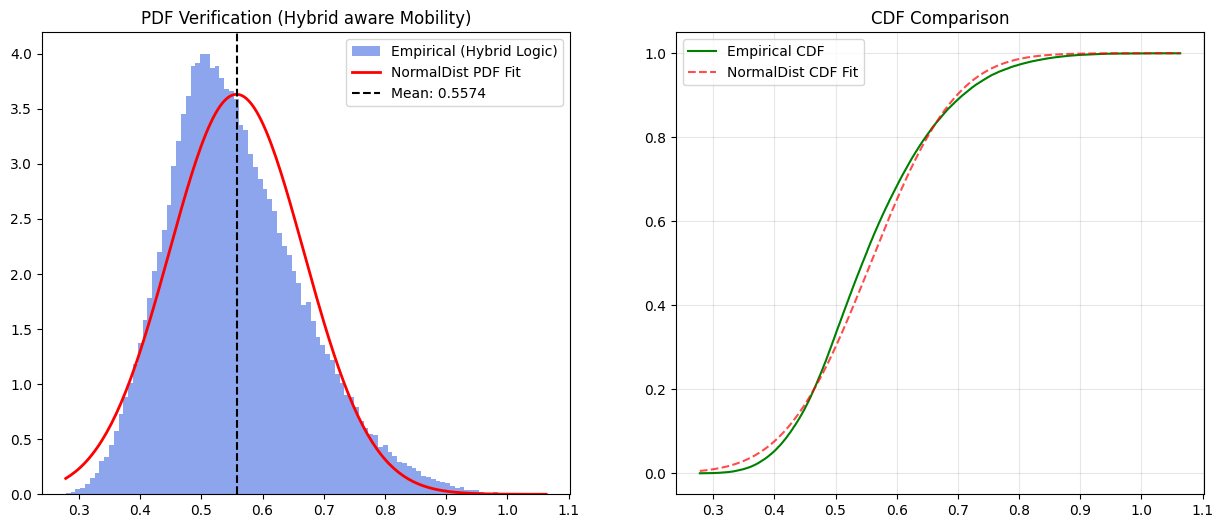

--- KẾT QUẢ CALIBRATE GỐC ---
Mean (MU_DELTA): 0.5574
Std (SIGMA_DELTA): 0.1099
Skewness: 0.5727
Kurtosis: 0.2435


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from statistics import NormalDist
import pandas as pd

def _calculate_delta(env_config):
    mobility_weights = np.array([0.2, 0.7, 0.1])
    mobility_probs = np.array([
        env_config["walk_prob"], 
        env_config["vehicle_prob"], 
        env_config["staionary_prob"]
    ])

    slice_weights = np.array([0.4, 0.4, 0.2])
    slice_probs = np.array([
        env_config["embb_prob"], 
        env_config["urllc_prob"], 
        env_config["mmtc_prob"]
    ])

    m_demand = np.dot(mobility_probs, mobility_weights)

    # Logic: net_rate / (1 + |net_rate|) -> Giới hạn stress trong khoảng (-1, 1)
    net_rate = env_config["arrival_rate"] / (env_config["departure_rate"] + 1e-6)
    norm_net_rate = net_rate / (net_rate + 1)
    
    stress = norm_net_rate * m_demand
    qos_demand = np.dot(slice_probs, slice_weights)
    
    delta = qos_demand + stress
    return delta

def plot_original_logic_verification(n_samples=100000):
    deltas = []
    for _ in range(n_samples):
        p = np.random.dirichlet([1, 1, 1])
        q = np.random.dirichlet([1, 1, 1])
        a = np.random.uniform(0.1, 5.0)
        d = np.random.uniform(0.1, a)
        rand_config = {
            "arrival_rate": a,
            "departure_rate": d,
            "walk_prob": p[0], "vehicle_prob": p[1], "staionary_prob": p[2],
            "embb_prob": q[0], "urllc_prob": q[1], "mmtc_prob": q[2]
        }
        deltas.append(_calculate_delta(rand_config))
    
    deltas = np.array(deltas)
    mu, std = np.mean(deltas), np.std(deltas)

    dist = NormalDist(mu, std)

    # Vẽ đồ thị
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    x = np.linspace(min(deltas), max(deltas), 200)

    # 1. PDF
    ax1.hist(deltas, bins=100, density=True, alpha=0.6, color='royalblue', label='Empirical (Hybrid Logic)')
    # Dùng list comprehension với dist.pdf() của NormalDist
    y_pdf = [dist.pdf(val) for val in x]
    ax1.plot(x, y_pdf, 'r-', lw=2, label='NormalDist PDF Fit')
    ax1.axvline(mu, color='black', linestyle='--', label=f'Mean: {mu:.4f}')
    ax1.set_title("PDF Verification (Hybrid aware Mobility)")
    ax1.legend()

    # 2. CDF
    ax2.plot(np.sort(deltas), np.linspace(0, 1, len(deltas)), label='Empirical CDF', color='green')
    y_cdf = [dist.cdf(val) for val in x]
    ax2.plot(x, y_cdf, 'r--', alpha=0.7, label='NormalDist CDF Fit')
    ax2.set_title("CDF Comparison")
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    plt.show()

    deltas_series = pd.Series(deltas)
    print(f"--- KẾT QUẢ CALIBRATE GỐC ---")
    print(f"Mean (MU_DELTA): {mu:.4f}")
    print(f"Std (SIGMA_DELTA): {std:.4f}")
    print(f"Skewness: {deltas_series.skew():.4f}")
    print(f"Kurtosis: {deltas_series.kurt():.4f}")

plot_original_logic_verification()

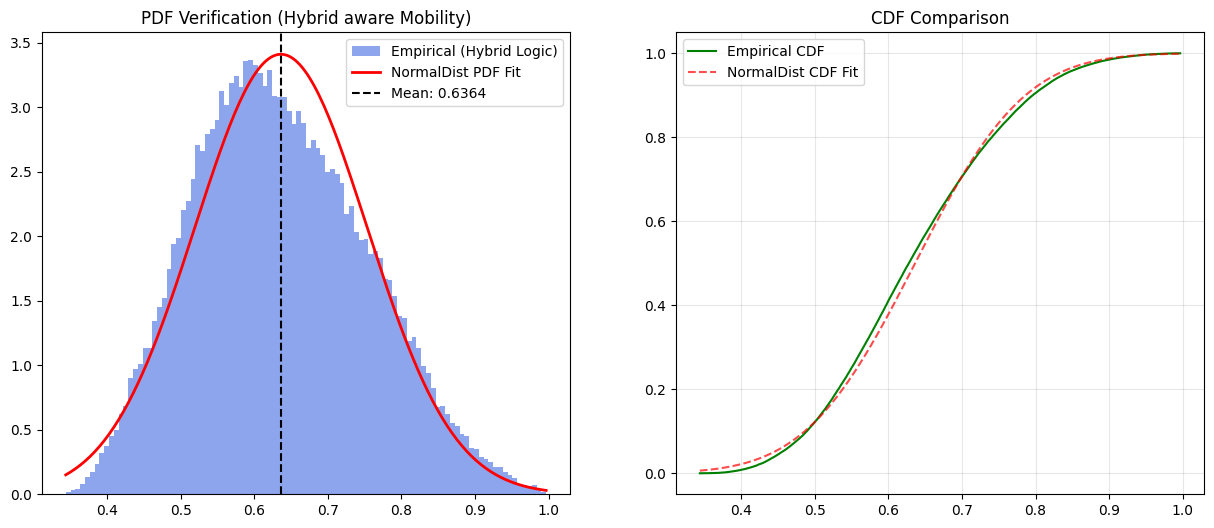

Mean (MU_DELTA): 0.6364
Std (SIGMA_DELTA): 0.1170
Skewness: 0.2609
Kurtosis: -0.4161


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from statistics import NormalDist
import math

def _calculate_jain_demand(env_config):
    # 1. Service Demand (Slice)
    # weights: eMBB=0.4, URLLC=0.4, mMTC=0.2
    s_demands = np.array([
        env_config["embb_prob"] * 0.4,
        env_config["urllc_prob"] * 0.4,
        env_config["mmtc_prob"] * 0.2
    ])
    jain_s = (np.sum(s_demands)**2) / (3 * np.sum(s_demands**2) + 1e-9)

    # 2. Mobility Demand
    # weights: Walk=0.2, Vehicle=0.7, Stationary=0.1
    m_demands = np.array([
        env_config["walk_prob"] * 0.2,
        env_config["vehicle_prob"] * 0.7,
        env_config["staionary_prob"] * 0.1
    ])
    jain_m = (np.sum(m_demands)**2) / (3 * np.sum(m_demands**2) + 1e-9)

    jain_total = math.sqrt(jain_s * jain_m)
    return jain_total, jain_s, jain_m

def plot_fairness_verification(n_samples=100000):
    omegas = []
    for _ in range(n_samples):
        p = np.random.dirichlet([1, 1, 1])
        q = np.random.dirichlet([1, 1, 1])
        conf = {
            "walk_prob": p[0], "vehicle_prob": p[1], "staionary_prob": p[2],
            "embb_prob": q[0], "urllc_prob": q[1], "mmtc_prob": q[2]
        }
        omega, _, _ = _calculate_jain_demand(conf)
        omegas.append(omega)
    
    omegas = np.array(omegas)
    mu, std = np.mean(omegas), np.std(omegas)

    dist = NormalDist(mu, std)

    # Vẽ đồ thị
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    x = np.linspace(min(omegas), max(omegas), 200)

    # 1. PDF
    ax1.hist(omegas, bins=100, density=True, alpha=0.6, color='royalblue', label='Empirical (Hybrid Logic)')
    # Dùng list comprehension với dist.pdf() của NormalDist
    y_pdf = [dist.pdf(val) for val in x]
    ax1.plot(x, y_pdf, 'r-', lw=2, label='NormalDist PDF Fit')
    ax1.axvline(mu, color='black', linestyle='--', label=f'Mean: {mu:.4f}')
    ax1.set_title("PDF Verification (Hybrid aware Mobility)")
    ax1.legend()

    # 2. CDF
    ax2.plot(np.sort(omegas), np.linspace(0, 1, len(omegas)), label='Empirical CDF', color='green')
    y_cdf = [dist.cdf(val) for val in x]
    ax2.plot(x, y_cdf, 'r--', alpha=0.7, label='NormalDist CDF Fit')
    ax2.set_title("CDF Comparison")
    ax2.grid(True, alpha=0.3)
    ax2.legend()

    plt.show()

    series = pd.Series(omegas)
    print(f"Mean (MU_DELTA): {mu:.4f}")
    print(f"Std (SIGMA_DELTA): {std:.4f}")
    print(f"Skewness: {series.skew():.4f}")
    print(f"Kurtosis: {series.kurt():.4f}")

plot_fairness_verification()

In [13]:
import numpy as np
from statistics import NormalDist
import math

def _calculate_preference(env_config):
    mobility_weights = np.array([0.2, 0.7, 0.1])
    mobility_probs = np.array([
        env_config["walk_prob"], 
        env_config["vehicle_prob"], 
        env_config["staionary_prob"]
    ])

    slice_weights = np.array([0.4, 0.4, 0.2])
    slice_probs = np.array([
        env_config["embb_prob"], 
        env_config["urllc_prob"], 
        env_config["mmtc_prob"]
    ])

    m_stress = np.dot(mobility_probs, mobility_weights)

    dynamic_ratio = env_config["arrival_rate"] / (env_config["departure_rate"] + 1e-6)
    norm_dynamic_ratio = dynamic_ratio / (dynamic_ratio + 1)
    
    dynamic_stress = norm_dynamic_ratio * m_stress
    qos_demand = np.dot(slice_probs, slice_weights)
    
    pressure = qos_demand + dynamic_stress
    return {
        "qos_demand": round(qos_demand, 4),
        "dynamic_ratio": round(dynamic_ratio, 4),
        "m_stress": round(m_stress, 4),
        "dynamic_stress": round(dynamic_stress, 4),
        "raw_pressure": round(pressure, 4)
    }

def _calculate_jain_demand(env_config):
    # 1. Service Demand (Slice)
    # weights: eMBB=0.4, URLLC=0.4, mMTC=0.2
    s_demands = np.array([
        env_config["embb_prob"] * 0.4,
        env_config["urllc_prob"] * 0.4,
        env_config["mmtc_prob"] * 0.2
    ])
    jain_s = (np.sum(s_demands)**2) / (3 * np.sum(s_demands**2) + 1e-9)

    # 2. Mobility Demand
    # weights: Walk=0.2, Vehicle=0.7, Stationary=0.1
    m_demands = np.array([
        env_config["walk_prob"] * 0.2,
        env_config["vehicle_prob"] * 0.7,
        env_config["staionary_prob"] * 0.1
    ])
    jain_m = (np.sum(m_demands)**2) / (3 * np.sum(m_demands**2) + 1e-9)

    jain_total = math.sqrt(jain_s * jain_m)
    return {
        "raw_jain": round(jain_total, 4),
        "jain_m": round(jain_m, 4),
        "jain_s": round(jain_s, 4)
    }

# cdf map z (position of current value) in gauss dist plot to [0,1]
# cdf describe area -inf to z: x,z,cdf co_variable + cdf(z) also show the relate between x and mean 
def _calculate_pressure_calibrated(raw_pressure):
    mean = 0.5679
    std = 0.2429

    z_score = (raw_pressure - mean)/std

    # Aware energy around mean value
    # --> mean + std is the expected value to allow greedy use energy to push qos
    pressure = NormalDist(mu=mean, sigma=std).cdf(z_score)
    return pressure

def _calculate_jain_calibrated(raw_jain):
    mean = 0.6372
    std = 0.1172
    z_score = (raw_jain - mean)/std

    jain = NormalDist(mu=mean, sigma=std).cdf(z_score)
    return jain 


def _get_env_penalty(env_config, w_qos, w_energy, w_fairness):
    pref = _calculate_preference(env_config)
    raw_pressure = pref['raw_pressure']
    pressure = _calculate_pressure_calibrated(raw_pressure)

    jain_pref = _calculate_jain_demand(env_config)
    raw_jain = jain_pref["raw_jain"]
    jain = _calculate_jain_calibrated(raw_jain)

    ratio_factor = w_qos / (w_energy + 1e-6)
    # Higher pressure, lower energy penalty ~ Harder env, allow more energy usage
    energy_penalty = ratio_factor * (1 - pressure)

    # Raw Jain [0,1]: 1 is totally fair
    # --> (1 - jain) Less jain = More penalty
    # --> (1 - pressure) More stable - more aware to fairness
    # fairness_penalty = (1 / (w_fairness + 1e-6)) * (1 - pressure) * (1 - jain)
    fairness_penalty = (1 / (w_fairness + 1e-6)) * (1 - jain)

    penalty = fairness_penalty + energy_penalty
    return {
        "env_penalty": round(penalty, 4),
        "energy_penalty": round(energy_penalty, 4),
        "fairness_penalty": round(fairness_penalty, 4),
        **pref,
        "pressure": round(pressure, 4),
        **jain_pref,
        "jain": round(jain, 4)
    }

In [14]:
env_test =   {
    "name": "C10_Desert_Silence",
    "arrival_rate": 0.3,
    "departure_rate": 0.3,
    "walk_prob": 0.1, "vehicle_prob": 0.1, "staionary_prob": 0.8,
    "embb_prob": 0.1, "urllc_prob": 0.1, "mmtc_prob": 0.8,
  }

print(f"{env_test}\n")

res_1 = _get_env_penalty(env_test, w_qos=8.0, w_energy=1.0, w_fairness=1.0)
print(f"Env Penalty: {res_1}")

res_2 = _get_env_penalty(env_test, w_qos=7.0, w_energy=2.0, w_fairness=1.0)
print(f"Env Penalty: {res_2}")

res_3 = _get_env_penalty(env_test, w_qos=6.0, w_energy=2.0, w_fairness=2.0)
print(f"Env Penalty: {res_3}")

res_4 = _get_env_penalty(env_test, w_qos=5.0, w_energy=3.0, w_fairness=2.0)
print(f"Env Penalty: {res_4}")

{'name': 'C10_Desert_Silence', 'arrival_rate': 0.3, 'departure_rate': 0.3, 'walk_prob': 0.1, 'vehicle_prob': 0.1, 'staionary_prob': 0.8, 'embb_prob': 0.1, 'urllc_prob': 0.1, 'mmtc_prob': 0.8}

Env Penalty: {'env_penalty': 8.0173, 'energy_penalty': 8.0, 'fairness_penalty': 0.0173, 'qos_demand': np.float64(0.24), 'dynamic_ratio': 1.0, 'm_stress': np.float64(0.17), 'dynamic_stress': np.float64(0.085), 'raw_pressure': np.float64(0.325), 'pressure': 0.0, 'raw_jain': 0.7409, 'jain_m': np.float64(0.8234), 'jain_s': np.float64(0.6667), 'jain': 0.9827}
Env Penalty: {'env_penalty': 3.5173, 'energy_penalty': 3.5, 'fairness_penalty': 0.0173, 'qos_demand': np.float64(0.24), 'dynamic_ratio': 1.0, 'm_stress': np.float64(0.17), 'dynamic_stress': np.float64(0.085), 'raw_pressure': np.float64(0.325), 'pressure': 0.0, 'raw_jain': 0.7409, 'jain_m': np.float64(0.8234), 'jain_s': np.float64(0.6667), 'jain': 0.9827}
Env Penalty: {'env_penalty': 3.0087, 'energy_penalty': 3.0, 'fairness_penalty': 0.0087, 'qos_

In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import json

def merge_jsonl(input_dir="logs"):
    input_path = Path(input_dir)

    kb_files = sorted(input_path.glob("kb*.jsonl"))
    none_files = sorted(input_path.glob("none*.jsonl"))
    zs_files = sorted(input_path.glob("zs_*.jsonl"))
    fs_files = sorted(input_path.glob("fs_*.jsonl"))

    def merge(files, output_file):
        with open(output_file, "w", encoding="utf-8") as outfile:
            for file in files:
                with open(file, "r", encoding="utf-8") as infile:
                    for line in infile:
                        outfile.write(line)

    merge(kb_files, f"{input_dir}/kb_merged.jsonl")
    merge(none_files, f"{input_dir}/none_merged.jsonl")
    merge(zs_files, f"{input_dir}/zs_merged.jsonl")
    merge(fs_files, f"{input_dir}/fs_merged.jsonl")

    print(f"Merged {len(kb_files)} kb files → kb_merged.jsonl")
    print(f"Merged {len(none_files)} none files → none_merged.jsonl")
    print(f"Merged {len(zs_files)} zs files → zs_merged.jsonl")
    print(f"Merged {len(fs_files)} fs files → fs_merged.jsonl")



def load_metrics(file_path):
    qos, energy, fairness, score, reward = [], [], [], [], []

    with open(file_path, "r", encoding="utf-8") as f:
        for line in f:
            data = json.loads(line)

            qos.append(data.get("qos", 0))
            energy.append(data.get("energy_usage", 0))
            fairness.append(data.get("fairness", 0))
            score.append(data.get("score", 0))
            reward.append(data.get("reward", 0))

    return {
        "qos": qos,
        "energy_usage": energy,
        "fairness": fairness,
        "score": score,
        "reward": reward
    }


def plot_and_save(folder="logs", output_dir="logs"):
    folder = Path(folder)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    files = sorted(folder.glob("*_merged.jsonl"))
    all_data = {f.stem: load_metrics(f) for f in files}

    metrics = ["qos", "energy_usage", "fairness", "score", "reward"]

    # ---- Combined subplot ----
    fig, axes = plt.subplots(5, 1, figsize=(10, 16), sharex=True)

    for i, metric in enumerate(metrics):
        ax = axes[i]
        for name, data in all_data.items():
            y = data[metric]
            x = range(len(y))
            ax.plot(x, y, label=name)

        ax.set_title(metric)
        ax.set_ylabel(metric)
        ax.legend()

    axes[-1].set_xlabel("Step")
    plt.tight_layout()

    combined_path = output_dir / "comparison_all_metrics.png"
    plt.savefig(combined_path)
    plt.close()

    print(f"Saved: {combined_path}")

    # ---- Optional: individual plots ----
    for metric in metrics:
        plt.figure()
        for name, data in all_data.items():
            y = data[metric]
            x = range(len(y))
            plt.plot(x, y, label=name)

        plt.title(metric)
        plt.xlabel("Step")
        plt.ylabel(metric)
        plt.legend()
        plt.tight_layout()

        path = output_dir / f"{metric}.png"
        plt.savefig(path)
        plt.close()

        print(f"Saved: {path}")


if __name__ == "__main__":
    merge_jsonl()
    plot_and_save()